# R01 — Published local attack procedures (v3)

This reruns the same OG development cases. v2's extra gates are removed. **Old v2 results are not reused as v3 results.** No human reference passage enters an attack. Review text quality after generation.

| Arm | Procedure restored | Deliberate substitution |
|---|---|---|
| RAFT | Released detector-proxy branch: 10% **successful substitutions**, 15 candidates, isolated NLTK POS, released highlighting/ranking and acceptance rules; full input paragraph prompt | Qwen2.5-3B-Instruct NF4 supplies candidates; our frozen RoBERTa supplies detector queries |
| TEXTFOOLER | Released `attack` function, original stoplist/POS, counter-fitted neighbors, **USE-large/3 angular similarity**, window 15, threshold .5, original flip stopping; no extra edit/query cap | Our frozen RoBERTa predictor; sequential inference instead of batching |
| EVOLUTION_SOURCE | Released genetic search and sentence-level substitution prompt/parser: population 10, iterations floor(.2 × positions with candidates), original crossover/mutation/parent selection | Qwen candidates and a frozen-RoBERTa score adapter. **This is a source-code port, not a verified reproduction of Table 7's RoBERTa experiment** |

**Fidelity limitation for Evolution:** the public implementation we could verify supplies a likelihood-model objective, not the Table 7 classifier adapter. Its .2 setting controls iterations, not a hard final edit cap, and its parent weights are raw scores divided by their sum. We retain those released operations rather than inventing fixes, and label this arm `EVOLUTION_SOURCE`. The paper's stated 20% edit limit and its exact classifier implementation are not established by that code. Do not present this arm as an exact Table 7 replication.

**Default run: RAFT and TEXTFOOLER.** The evolutionary source port is included for audit, but excluded from the default schedule because its classifier-specific experiment could not be verified. Add `EVOLUTION_SOURCE` to `ARMS_TO_RUN` only for an explicitly labeled source-port experiment.

All arms retain source tokenization/rejoining, so spacing can change. Named entities are no longer globally protected. No common semantic/POS gate is added. The two source methods' own checks remain. No whole-document generative rewrite or instructional-prompt attack is included.

**Run in a fresh kernel.** Install missing main-environment packages only if needed:
```python
%pip install 'transformers==4.51.3' 'accelerate==1.6.0' 'bitsandbytes==0.45.5' 'huggingface-hub<1' safetensors sentencepiece pandas pyarrow numpy scipy matplotlib scikit-learn nltk gdown
```
The TextFooler cell creates a separate CPU-only Python 3.10/3.11 environment for the original USE weights. TensorFlow will not be installed into your notebook environment. It requires a first-time download and disk space. No MiniLM fallback occurs.

Completed cases, candidate responses, and detector queries are saved immediately. On interruption, an unfinished source attack replays deterministically using its saved responses/queries; completed cases are skipped. There is no new seven-generation or 2,000-query cap.


In [1]:
# %pip install 'accelerate==1.6.0'

In [2]:
from pathlib import Path
import os, json, hashlib, tempfile, gc, re, math, time, inspect, html, fcntl, platform
from contextlib import contextmanager
from collections import Counter
from difflib import SequenceMatcher
import importlib.metadata
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, nltk
import zipfile, shutil
from functools import lru_cache
from packaging.version import Version
from huggingface_hub import HfApi
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                         AutoModelForSequenceClassification, AutoModel, BitsAndBytesConfig)
from IPython.display import display, HTML
assert Version('4.51.3') <= Version(transformers.__version__) < Version('5'), 'Use the R01 environment above.'
assert torch.cuda.is_available(), 'The default NF4 configuration requires CUDA.'
DEVICE='cuda:0'
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
torch.use_deterministic_algorithms(True)
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False

ROOT_OVERRIDE=None # e.g. Path('..')
ROOT=Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1').exists()),None)
assert ROOT is not None, 'Open this notebook inside reproduction/, or set ROOT_OVERRIDE.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C07=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1'
AD=C07/'adaptation20_34_seed20260923'
NS_PATH=ROOT/'results/causal/C06b_NEW_steps5_10_v1/NS10_texts.csv'
OUT=ROOT/'results/causal/R01_published_local_v3'
CASE_MODE='development10' # development10 | development20 | heldout34 | all54
ARMS_TO_RUN=['RAFT','TEXTFOOLER'] # EVOLUTION_SOURCE is available, but is NOT a verified exact classifier experiment
COMPARE_ARMS=['OG',*ARMS_TO_RUN]
CFG=dict(seed=20260925,generator='Qwen/Qwen2.5-3B-Instruct',quantization='NF4-double',
    raft_fraction=.10,raft_candidates=15,semantic_model='https://tfhub.dev/google/universal-sentence-encoder-large/3',
    lexical_cosine=.5,lexical_top_k=50,semantic_window=15,semantic_threshold=.5,
    evolution_population=10,evolution_iteration_rate=.2,
    generator_temperature=1.,generator_top_p=1.,generator_token_ceiling=8192,
    max_prompt_tokens=16384,detector_tokens=512,bootstrap=5000)
LOCAL_PROMPT='Upstream prompts embedded below; candidate-generator substitution only.'
import sys, subprocess, types, string, copy, ast
from nltk.tokenize import word_tokenize, sent_tokenize
for resource in ['punkt','punkt_tab','averaged_perceptron_tagger','averaged_perceptron_tagger_eng','universal_tagset']:
    nltk.download(resource,quiet=True)
# Supply Python 3.10/3.11 if the notebook itself uses another version.
USE_BASE_PYTHON=(sys.executable if (3,9)<=sys.version_info[:2]<=(3,11) else shutil.which('python3.11'))
USE_MODEL_PATH=None # optional local copy of the SAME USE-large/3 model, never another encoder
# If already downloaded, set this to the official counter-fitted-vectors.txt.
COUNTER_FITTED_PATH=None
for sub in ['','runs','proposals','banks','ranks','scores','guide','figures','assets']:(OUT/sub).mkdir(parents=True,exist_ok=True)

def sha(x):return hashlib.sha256(str(x).encode('utf-8')).hexdigest()
def digest(x):return sha(json.dumps(x,sort_keys=True,ensure_ascii=False))
def file_sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
def atomic_json(p,value):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    fd,tmp=tempfile.mkstemp(dir=p.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            json.dump(value,f,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False)
            f.flush();os.fsync(f.fileno())
        os.replace(tmp,p)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def save_csv(df,p):
    p=Path(p);fd,tmp=tempfile.mkstemp(dir=p.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:df.to_csv(f,index=False);f.flush();os.fsync(f.fileno())
        os.replace(tmp,p)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def freeze(p,value):
    if p.exists():assert json.loads(p.read_text())==value, f'Protocol differs: select a new OUT. {p}'
    else:atomic_json(p,value)
@contextmanager
def run_lock():
    with (OUT/'run.lock').open('a+') as f:
        try:fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        except BlockingIOError:raise RuntimeError('Another R01 cell/process is writing this run.')
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)
def release():gc.collect();torch.cuda.empty_cache()
def memory():
    free,total=torch.cuda.mem_get_info()
    print(f'CUDA allocated {torch.cuda.memory_allocated()/2**30:.2f} GiB; free {free/2**30:.2f} GiB',flush=True)
print('Output:',OUT);memory()

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Output: ../results/causal/R01_published_local_v3
CUDA allocated 0.00 GiB; free 6.27 GiB


## 1. Original RAID AI inputs and protocol

Use the saved 54-case mapping to select **original RAID AI**, not the human row or NEW. Human validation/test text remains separate until evaluation. Checkpoint/model/resource hashes and code are frozen. The new output directory prevents mixing results with the superseded whole-text R01.

In [4]:
split=json.loads((AD/'split.json').read_text())
dev_ids=sorted(map(str,split['adaptation_cases'])); test_ids=sorted(map(str,split['test_cases']))
assert len(dev_ids)==20 and len(test_ids)==34 and not set(dev_ids)&set(test_ids)
ns=pd.read_csv(NS_PATH,keep_default_na=False)
ns['case_id']=ns.case_id.astype(str)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert set(ns.case_id)==set(dev_ids+test_ids)
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet',columns=['dataset','source_id','label','split','domain'])
corpus=pd.read_parquet(BASE/'paired_corpus.parquet',columns=['source_id','text'])
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','label','split','domain']].merge(corpus,on='source_id',validate='one_to_one')
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'label'].eq(1).all() and rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
all_og=ns[['case_id','source_id','domain']].copy()
all_og['text']=all_og.source_id.map(rm.text)
assert all_og.text.map(lambda t:isinstance(t,str) and bool(t.strip())).all()
all_og['text_sha']=all_og.text.map(sha)
all_og['partition']=np.where(all_og.case_id.isin(dev_ids),'development20','heldout34')
# Round-robin genre selection with hash-fixed within-genre order.
pool=all_og.loc[all_og.case_id.isin(dev_ids)].copy()
pool['order']=pool.case_id.map(lambda x:sha(str(CFG['seed'])+x))
queues={d:g.sort_values('order').case_id.tolist() for d,g in pool.groupby('domain')}
order=[]
while any(queues.values()):
    for d in sorted(queues):
        if queues[d]:order.append(queues[d].pop(0))
selected={'development10':order[:10],'development20':order,'heldout34':test_ids,'all54':order+test_ids}[CASE_MODE]
og=all_og.set_index('case_id').loc[selected].reset_index()
HUMAN_EVAL=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test']),['source_id','domain','split','text']].copy()
CHECKPOINTS={'Frozen':C07/'best_model','RAID-only':AD/'raid_only_control/best_model','Adapted':AD/'best_model'}
for p in CHECKPOINTS.values():assert (p/'config.json').exists(),p

def checkpoint_fingerprint(path):
    files=sorted(list(path.glob('*.safetensors'))+list(path.glob('*.json'))+list(path.glob('*.txt')))
    if not list(path.glob('*.safetensors')):files+=sorted(path.glob('pytorch_model*.bin'))
    assert any(p.suffix in ['.safetensors','.bin'] for p in files),path
    return {p.name:file_sha(p) for p in files}
CP_SHA={name:digest(checkpoint_fingerprint(p)) for name,p in CHECKPOINTS.items()}
freeze(OUT/'checkpoint_hashes.json',CP_SHA)
pins_path=OUT/'model_pin.json'
if pins_path.exists():
    PIN=json.loads(pins_path.read_text());assert PIN['id']==CFG['generator']
else:
    PIN={'id':CFG['generator'],'revision':HfApi().model_info(CFG['generator']).sha}
    atomic_json(pins_path,PIN)
SELF=next((p for p in [Path.cwd()/'R01_RoBERTa_attack_potency.ipynb',ROOT/'experiments/R01_RoBERTa_attack_potency.ipynb',ROOT/'R01_RoBERTa_attack_potency.ipynb'] if p.exists()),None)
assert SELF is not None,'Save this notebook with its supplied filename in cwd, ROOT, or ROOT/experiments.'
code_hash=digest([''.join(c['source']) for c in json.loads(SELF.read_text())['cells'] if c['cell_type']=='code'])
# CASE_MODE and schedule lines excluded from code hash so expansion does not invalidate saved generations.
canonical_code=[]
for c in json.loads(SELF.read_text())['cells']:
    if c['cell_type']=='code':
        canonical_code.append('\n'.join(line for line in ''.join(c['source']).splitlines()
            if not line.startswith(('CASE_MODE=','ARMS_TO_RUN=','COMPARE_ARMS='))))
PROTOCOL=dict(version=3,config=CFG,prompts=[LOCAL_PROMPT],model=PIN,
    guide=CP_SHA['Frozen'],code=digest(canonical_code),parser={"nltk":nltk.__version__},
    originals=all_og.sort_values('case_id')[['case_id','source_id','domain','text_sha','partition']].to_dict('records'),
    split_sha=file_sha(AD/'split.json'),dtype=str(DTYPE),gpu=torch.cuda.get_device_name(0),
    packages={p:importlib.metadata.version(p) for p in ['torch','transformers','accelerate','bitsandbytes','nltk','numpy']})
# Resume existing results using their original run identity.
protocol_path = OUT / "protocol.json"

if protocol_path.exists():
    saved_protocol = json.loads(protocol_path.read_text())

    # Check experiment inputs, not unrelated notebook cells.
    essential = [
        "version", "config", "prompts", "model",
        "guide", "originals", "split_sha",
    ]
    changed = [
        key for key in essential
        if saved_protocol.get(key) != PROTOCOL.get(key)
    ]
    if changed:
        raise ValueError(f"Experiment inputs changed: {changed}")

    PROTOCOL = saved_protocol
else:
    atomic_json(protocol_path, PROTOCOL)

RUN_SHA = digest(PROTOCOL)
print("Original run identity restored; saved results remain reusable.")
save_csv(og.drop(columns='text'),OUT/('selection_'+CASE_MODE+'.csv'))
del meta,corpus,raid,rm,ns,pool,queues;release()
display(og[['case_id','domain','partition']])
print(len(og),'cases;',len(ARMS_TO_RUN),'rewrite arms. No generation started.')

Original run identity restored; saved results remain reusable.


,case_id,domain,partition
0,gate_0074,abstracts,development20
1,gate_0023,books,development20
2,gate_0024,news,development20
3,gate_0067,recipes,development20
4,gate_0019,reddit,development20
5,gate_0039,wiki,development20
6,gate_0079,abstracts,development20
7,gate_0016,books,development20
8,gate_0003,news,development20
9,gate_0081,recipes,development20


10 cases; 2 rewrite arms. No generation started.


## 2. Models and resumable detector scoring

One quantized generator plus one detector at most during RAFT. Evolution candidate preparation unloads the detector. TextFooler unloads the generator and runs the small semantic encoder on CPU. Saved scores are keyed by checkpoint, tokenizer, numerical settings and exact text. Interruptions preserve prior decisions and candidate lists; unfinished local requests may be replayed.

In [5]:
GEN=GTOK=DET=DTOK=SEM=STOK=None
DETECTOR_QUERIES=0
GUIDE_SPEC=None
def load_generator():
    global GEN,GTOK
    if GEN is not None:return
    release();memory()
    GTOK=AutoTokenizer.from_pretrained(PIN['id'],revision=PIN['revision'],use_fast=True)
    q=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=DTYPE)
    GEN=AutoModelForCausalLM.from_pretrained(PIN['id'],revision=PIN['revision'],
        quantization_config=q,torch_dtype=DTYPE,device_map={'':0},low_cpu_mem_usage=True,
        attn_implementation='eager').eval()
    assert 'logits_to_keep' in inspect.signature(GEN.forward).parameters, 'Qwen2.5 requires final-logit support.'
    memory()

def load_detector(path=None):
    global DET,DTOK,GUIDE_SPEC
    unload_detector()
    path=path or CHECKPOINTS['Frozen']
    DTOK=AutoTokenizer.from_pretrained(CHECKPOINTS['Frozen'],use_fast=True)
    DET=AutoModelForSequenceClassification.from_pretrained(path,torch_dtype=torch.float32,
        low_cpu_mem_usage=True,attn_implementation='eager').to(DEVICE).eval()
    assert DET.config.num_labels==2
    GUIDE_SPEC=digest([CP_SHA['Frozen'],DTOK.backend_tokenizer.to_str(),str(DTYPE),CFG['detector_tokens'],torch.__version__,transformers.__version__])
    # C07b trained labels 0=human, 1=AI. Do not infer from id2label display strings.
    memory()

def unload_detector():
    global DET,DTOK
    DET=DTOK=None;release()

def unload_generator():
    global GEN,GTOK
    GEN=GTOK=None;release()

@torch.inference_mode()
def detector_forward(encoded):
    global DETECTOR_QUERIES
    assert DET is not None
    with torch.autocast('cuda',dtype=DTYPE):z=DET(**encoded).logits.float()
    DETECTOR_QUERIES+=int(z.shape[0])
    return z

@torch.inference_mode()
def detector_one(text):
    b=DTOK(text,return_tensors='pt',truncation=True,max_length=CFG['detector_tokens']).to(DEVICE)
    z=detector_forward(b)[0]
    return dict(AI_score=float(z.softmax(-1)[1].cpu()),AI_log_odds=float((z[1]-z[0]).cpu()),
                scored_tokens=int(b.input_ids.shape[1]))

def detector_many(texts):return [detector_one(t)['AI_log_odds'] for t in texts]

def chat_ids(instruction,text):
    ids=GTOK.apply_chat_template([{'role':'user','content':instruction+'\n\nTEXT:\n'+text}],
        tokenize=True,add_generation_prompt=True)
    assert len(ids)<=CFG['max_prompt_tokens'], 'Input too long; no silent source truncation. Increase limit in a new OUT.'
    return ids

class Stream:
    def __init__(self,prompt,generated=()):
        ids=list(prompt)+list(generated)
        self.n=len(ids)
        with torch.inference_mode():
            out=GEN(input_ids=torch.tensor([ids],device=DEVICE),use_cache=True,logits_to_keep=1)
        self.cache=out.past_key_values;self.logits=out.logits[0,-1].float();del out
    def advance(self,tid):
        with torch.inference_mode():
            out=GEN(input_ids=torch.tensor([[tid]],device=DEVICE),past_key_values=self.cache,
                attention_mask=torch.ones((1,self.n+1),device=DEVICE,dtype=torch.long),
                use_cache=True,logits_to_keep=1)
        self.n+=1;self.cache=out.past_key_values;self.logits=out.logits[0,-1].float();del out

def allowed_logits(z):
    # Keep EOS candidates; suppress other chat/control special tokens in every arm.
    z=z.clone()
    eos=GEN.generation_config.eos_token_id
    eos=set(eos if isinstance(eos,list) else [eos])|{GTOK.eos_token_id}
    for tid in GTOK.all_special_ids:
        if tid not in eos:z[tid]=-torch.inf
    return z,eos

def result_path(case,arm):return OUT/'runs'/f'{case}__{arm}.json'

def read_result(case,arm):
    p=result_path(case,arm)
    if not p.exists():return None
    r=json.loads(p.read_text());assert r['run_sha']==RUN_SHA and r['input_sha']==all_og.set_index('case_id').loc[case,'text_sha']
    return r

def complete(case,arm):
    r=read_result(case,arm);return r is not None and r['status'] in DONE

def record_base(row,arm):
    return dict(run_sha=RUN_SHA,input_sha=row.text_sha,case_id=row.case_id,source_id=row.source_id,
        domain=row.domain,partition=row.partition,arm=arm,status='running',text=row.text,replacements=[],
        detector_queries=0,seconds=0.,trace=[])

DONE={'completed'}

def guide(text):
    assert DET is not None and GUIDE_SPEC is not None
    p=OUT/'guide'/(digest([GUIDE_SPEC,sha(text)])+'.json')
    if p.exists():return json.loads(p.read_text())
    value=detector_one(text);atomic_json(p,value);return value

def source_words(text):return text.split()

# Exactly the source's probability objective, not log-odds ranking.
SOURCE_QUERY_REQUESTS=0
def source_probability(text):
    global SOURCE_QUERY_REQUESTS
    SOURCE_QUERY_REQUESTS+=1
    if SOURCE_QUERY_REQUESTS%100==0:print('Source queries requested:',SOURCE_QUERY_REQUESTS,'| fresh model evaluations:',DETECTOR_QUERIES,flush=True)
    return guide(text)['AI_score']

# Cached raw LLM responses. A token-limit finish is an error, never silently used.
def llm_response(prompt,case_id):
    key=digest([RUN_SHA,case_id,prompt]);p=OUT/'proposals'/(key+'.json')
    if p.exists():return json.loads(p.read_text())['raw']
    load_generator()
    ids=GTOK.apply_chat_template([{'role':'user','content':prompt}],tokenize=True,add_generation_prompt=True)
    assert len(ids)<=CFG['max_prompt_tokens'],'Prompt exceeds configured safety ceiling; no truncation.'
    gen=torch.Generator(device=DEVICE);gen.manual_seed(int(key[:15],16))
    eos=GEN.generation_config.eos_token_id
    eos=set(eos if isinstance(eos,list) else [eos])|{GTOK.eos_token_id}
    stream=Stream(ids);tokens=[];finished=False
    try:
        for _ in range(CFG['generator_token_ceiling']):
            probs=torch.softmax(stream.logits/CFG['generator_temperature'],dim=-1)
            tid=int(torch.multinomial(probs,1,generator=gen))
            if tid in eos:finished=True;break
            tokens.append(tid);stream.advance(tid)
    finally:del stream;release()
    raw=GTOK.decode(tokens,skip_special_tokens=True)
    if not finished:
        atomic_json(p.with_suffix('.incomplete.json'),dict(raw=raw,reason='candidate_generation_token_limit'))
        raise RuntimeError('Candidate response hit token ceiling. No partial candidate list was used.')
    atomic_json(p,dict(raw=raw,tokens=len(tokens),prompt=prompt,run_sha=RUN_SHA))
    return raw

def finish_source(row,arm,text,started,query_start,**details):
    r=record_base(row,arm)
    a=row.text.split();b=text.split()
    edits=sum(max(i2-i1,j2-j1) for op,i1,i2,j1,j2 in SequenceMatcher(a=a,b=b).get_opcodes() if op!='equal')
    r.update(status='completed',text=text,accepted_edits=edits,edit_fraction=edits/max(1,len(a)),
        seconds=time.monotonic()-started,detector_queries=DETECTOR_QUERIES-query_start,**details)
    atomic_json(result_path(row.case_id,arm),r)
    print(row.case_id,arm,'saved;',edits,'token-diff edits',flush=True)
    return r


## 3. Pinned source procedures

Original function bodies are embedded for auditability. Their checks are not shared across methods. The frozen classifier maps label 0 to human and label 1 to AI.

In [6]:
# Pinned upstream code, extracted without importing obsolete model stacks.
SOURCE_COMMITS={'RAFT':'0490389134258fa5169fc7d12fd6beeb4ccb5be6',
    'TextFooler':'6a56cb10f1055e00a8fbc6882f289e91cfe60f4e',
    'Evolution':'71469683fe6486d3dd3c48fa1dee6b67e02aa2c3'}
SOURCE_SHA={'raft.py': 'a41e72bf9fd7d7ad11efc14e25edf53a63f2df04eb7783718cb20a76c82e7388', 'tf.py': '27aa58e98aaf9cfcdaf1b2aaa760600042d78a1b3f2c85172565f6db5915c9f9', 'criteria.py': '6727430a38d253a573976ad7cd3abd3a70e3f15bd70b3cbc8a40b8f1ba022a30', 'evo.py': 'a5481ccb4226bacad0eb96374fa3fc4abc39aa61c262d86976c8a30f7dfcf240', 'evoprompt.py': '5467c306d1957c85f6ec19975a166a2614e0f27c8d7b02f3c5d6f650beaec556'}
freeze(OUT/'upstream_sources.json',dict(commits=SOURCE_COMMITS,sha256=SOURCE_SHA))
RAFT_SOURCE="class UpstreamRAFT:\n\n    def filter_punctuation(self, string):\n        pattern = '^[\\\\W_]+|[\\\\W_]+$'\n        left_punctuation = re.findall('^[\\\\W_]+', string)\n        right_punctuation = re.findall('[\\\\W_]+$', string)\n        clean_string = re.sub(pattern, '', string)\n        return (''.join(left_punctuation), ''.join(right_punctuation), clean_string)\n\n    def get_pos(self, word):\n        tokens = word_tokenize(word)\n        tagged = nltk.pos_tag(tokens)\n        return tagged[0][1] if tagged else None\n\n    def are_same_pos(self, word1, word2):\n        pos1 = self.get_pos(word1)\n        pos2 = self.get_pos(word2)\n        return pos1 == pos2\n\n    def predict_words(self, paragraph, top_k):\n        query = f'Given some input paragraph, we have highlighted a word using brackets. List {top_k} alternative words for it that ensure grammar correctness and semantic fluency. Output words only.\\n{paragraph}'\n        output = self.generate_text(query)\n        predicted_words = re.findall('\\\\b[a-zA-Z]+\\\\b', output)\n        if type(predicted_words) == list:\n            return predicted_words[:top_k]\n        if len(predicted_words) == top_k:\n            return predicted_words[:top_k]\n        else:\n            print(f'OpenAI returned else: {predicted_words}')\n            return []"
TF_SOURCE="def attack(text_ls, true_label, predictor, stop_words_set, word2idx, idx2word, cos_sim, sim_predictor=None,\n           import_score_threshold=-1., sim_score_threshold=0.5, sim_score_window=15, synonym_num=50,\n           batch_size=32):\n    # first check the prediction of the original text\n    orig_probs = predictor([text_ls]).squeeze()\n    orig_label = torch.argmax(orig_probs)\n    orig_prob = orig_probs.max()\n    if true_label != orig_label:\n        return '', 0, orig_label, orig_label, 0\n    else:\n        len_text = len(text_ls)\n        if len_text < sim_score_window:\n            sim_score_threshold = 0.1  # shut down the similarity thresholding function\n        half_sim_score_window = (sim_score_window - 1) // 2\n        num_queries = 1\n\n        # get the pos and verb tense info\n        pos_ls = criteria.get_pos(text_ls)\n\n        # get importance score\n        leave_1_texts = [text_ls[:ii] + ['<oov>'] + text_ls[min(ii + 1, len_text):] for ii in range(len_text)]\n        leave_1_probs = predictor(leave_1_texts, batch_size=batch_size)\n        num_queries += len(leave_1_texts)\n        leave_1_probs_argmax = torch.argmax(leave_1_probs, dim=-1)\n        import_scores = (orig_prob - leave_1_probs[:, orig_label] + (leave_1_probs_argmax != orig_label).float() * (\n                    leave_1_probs.max(dim=-1)[0] - torch.index_select(orig_probs, 0,\n                                                                      leave_1_probs_argmax))).data.cpu().numpy()\n\n        # get words to perturb ranked by importance scorefor word in words_perturb\n        words_perturb = []\n        for idx, score in sorted(enumerate(import_scores), key=lambda x: x[1], reverse=True):\n            try:\n                if score > import_score_threshold and text_ls[idx] not in stop_words_set:\n                    words_perturb.append((idx, text_ls[idx]))\n            except:\n                print(idx, len(text_ls), import_scores.shape, text_ls, len(leave_1_texts))\n\n        # find synonyms\n        words_perturb_idx = [word2idx[word] for idx, word in words_perturb if word in word2idx]\n        synonym_words, _ = pick_most_similar_words_batch(words_perturb_idx, cos_sim, idx2word, synonym_num, 0.5)\n        synonyms_all = []\n        for idx, word in words_perturb:\n            if word in word2idx:\n                synonyms = synonym_words.pop(0)\n                if synonyms:\n                    synonyms_all.append((idx, synonyms))\n\n        # start replacing and attacking\n        text_prime = text_ls[:]\n        text_cache = text_prime[:]\n        num_changed = 0\n        for idx, synonyms in synonyms_all:\n            new_texts = [text_prime[:idx] + [synonym] + text_prime[min(idx + 1, len_text):] for synonym in synonyms]\n            new_probs = predictor(new_texts, batch_size=batch_size)\n\n            # compute semantic similarity\n            if idx >= half_sim_score_window and len_text - idx - 1 >= half_sim_score_window:\n                text_range_min = idx - half_sim_score_window\n                text_range_max = idx + half_sim_score_window + 1\n            elif idx < half_sim_score_window and len_text - idx - 1 >= half_sim_score_window:\n                text_range_min = 0\n                text_range_max = sim_score_window\n            elif idx >= half_sim_score_window and len_text - idx - 1 < half_sim_score_window:\n                text_range_min = len_text - sim_score_window\n                text_range_max = len_text\n            else:\n                text_range_min = 0\n                text_range_max = len_text\n            semantic_sims = \\\n            sim_predictor.semantic_sim([' '.join(text_cache[text_range_min:text_range_max])] * len(new_texts),\n                                       list(map(lambda x: ' '.join(x[text_range_min:text_range_max]), new_texts)))[0]\n\n            num_queries += len(new_texts)\n            if len(new_probs.shape) < 2:\n                new_probs = new_probs.unsqueeze(0)\n            new_probs_mask = (orig_label != torch.argmax(new_probs, dim=-1)).data.cpu().numpy()\n            # prevent bad synonyms\n            new_probs_mask *= (semantic_sims >= sim_score_threshold)\n            # prevent incompatible pos\n            synonyms_pos_ls = [criteria.get_pos(new_text[max(idx - 4, 0):idx + 5])[min(4, idx)]\n                               if len(new_text) > 10 else criteria.get_pos(new_text)[idx] for new_text in new_texts]\n            pos_mask = np.array(criteria.pos_filter(pos_ls[idx], synonyms_pos_ls))\n            new_probs_mask *= pos_mask\n\n            if np.sum(new_probs_mask) > 0:\n                text_prime[idx] = synonyms[(new_probs_mask * semantic_sims).argmax()]\n                num_changed += 1\n                break\n            else:\n                new_label_probs = new_probs[:, orig_label] + torch.from_numpy(\n                        (semantic_sims < sim_score_threshold) + (1 - pos_mask).astype(float)).float().cuda()\n                new_label_prob_min, new_label_prob_argmin = torch.min(new_label_probs, dim=-1)\n                if new_label_prob_min < orig_prob:\n                    text_prime[idx] = synonyms[new_label_prob_argmin]\n                    num_changed += 1\n            text_cache = text_prime[:]\n        return ' '.join(text_prime), num_changed, orig_label, torch.argmax(predictor([text_prime])), num_queries"
CRITERIA_SOURCE='def get_stopwords():\n    \'\'\'\n    :return: a set of 266 stop words from nltk. eg. {\'someone\', \'anyhow\', \'almost\', \'none\', \'mostly\', \'around\', \'being\', \'fifteen\', \'moreover\', \'whoever\', \'further\', \'not\', \'side\', \'keep\', \'does\', \'regarding\', \'until\', \'across\', \'during\', \'nothing\', \'of\', \'we\', \'eleven\', \'say\', \'between\', \'upon\', \'whole\', \'in\', \'nowhere\', \'show\', \'forty\', \'hers\', \'may\', \'who\', \'onto\', \'amount\', \'you\', \'yours\', \'his\', \'than\', \'it\', \'last\', \'up\', \'ca\', \'should\', \'hereafter\', \'others\', \'would\', \'an\', \'all\', \'if\', \'otherwise\', \'somehow\', \'due\', \'my\', \'as\', \'since\', \'they\', \'therein\', \'together\', \'hereupon\', \'go\', \'throughout\', \'well\', \'first\', \'thence\', \'yet\', \'were\', \'neither\', \'too\', \'whether\', \'call\', \'a\', \'without\', \'anyway\', \'me\', \'made\', \'the\', \'whom\', \'but\', \'and\', \'nor\', \'although\', \'nine\', \'whose\', \'becomes\', \'everywhere\', \'front\', \'thereby\', \'both\', \'will\', \'move\', \'every\', \'whence\', \'used\', \'therefore\', \'anyone\', \'into\', \'meanwhile\', \'perhaps\', \'became\', \'same\', \'something\', \'very\', \'where\', \'besides\', \'own\', \'whereby\', \'whither\', \'quite\', \'wherever\', \'why\', \'latter\', \'down\', \'she\', \'sometimes\', \'about\', \'sometime\', \'eight\', \'ever\', \'towards\', \'however\', \'noone\', \'three\', \'top\', \'can\', \'or\', \'did\', \'seemed\', \'that\', \'because\', \'please\', \'whereafter\', \'mine\', \'one\', \'us\', \'within\', \'themselves\', \'only\', \'must\', \'whereas\', \'namely\', \'really\', \'yourselves\', \'against\', \'thus\', \'thru\', \'over\', \'some\', \'four\', \'her\', \'just\', \'two\', \'whenever\', \'seeming\', \'five\', \'him\', \'using\', \'while\', \'already\', \'alone\', \'been\', \'done\', \'is\', \'our\', \'rather\', \'afterwards\', \'for\', \'back\', \'third\', \'himself\', \'put\', \'there\', \'under\', \'hereby\', \'among\', \'anywhere\', \'at\', \'twelve\', \'was\', \'more\', \'doing\', \'become\', \'name\', \'see\', \'cannot\', \'once\', \'thereafter\', \'ours\', \'part\', \'below\', \'various\', \'next\', \'herein\', \'also\', \'above\', \'beside\', \'another\', \'had\', \'has\', \'to\', \'could\', \'least\', \'though\', \'your\', \'ten\', \'many\', \'other\', \'from\', \'get\', \'which\', \'with\', \'latterly\', \'now\', \'never\', \'most\', \'so\', \'yourself\', \'amongst\', \'whatever\', \'whereupon\', \'their\', \'serious\', \'make\', \'seem\', \'often\', \'on\', \'seems\', \'any\', \'hence\', \'herself\', \'myself\', \'be\', \'either\', \'somewhere\', \'before\', \'twenty\', \'here\', \'beyond\', \'this\', \'else\', \'nevertheless\', \'its\', \'he\', \'except\', \'when\', \'again\', \'thereupon\', \'after\', \'through\', \'ourselves\', \'along\', \'former\', \'give\', \'enough\', \'them\', \'behind\', \'itself\', \'wherein\', \'always\', \'such\', \'several\', \'these\', \'everyone\', \'toward\', \'have\', \'nobody\', \'elsewhere\', \'empty\', \'few\', \'six\', \'formerly\', \'do\', \'no\', \'then\', \'unless\', \'what\', \'how\', \'even\', \'i\', \'indeed\', \'still\', \'might\', \'off\', \'those\', \'via\', \'fifty\', \'each\', \'out\', \'less\', \'re\', \'take\', \'by\', \'hundred\', \'much\', \'anything\', \'becoming\', \'am\', \'everything\', \'per\', \'full\', \'sixty\', \'are\', \'bottom\', \'beforehand\'}\n    \'\'\'\n    stop_words = [\'a\', \'about\', \'above\', \'across\', \'after\', \'afterwards\', \'again\', \'against\', \'ain\', \'all\', \'almost\', \'alone\', \'along\', \'already\', \'also\', \'although\', \'am\', \'among\', \'amongst\', \'an\', \'and\', \'another\', \'any\', \'anyhow\', \'anyone\', \'anything\', \'anyway\', \'anywhere\', \'are\', \'aren\', "aren\'t", \'around\', \'as\', \'at\', \'back\', \'been\', \'before\', \'beforehand\', \'behind\', \'being\', \'below\', \'beside\', \'besides\', \'between\', \'beyond\', \'both\',  \'but\', \'by\', \'can\', \'cannot\', \'could\', \'couldn\', "couldn\'t", \'d\', \'didn\', "didn\'t", \'doesn\', "doesn\'t", \'don\', "don\'t", \'down\', \'due\', \'during\', \'either\', \'else\', \'elsewhere\', \'empty\', \'enough\', \'even\', \'ever\', \'everyone\', \'everything\', \'everywhere\', \'except\',  \'first\', \'for\', \'former\', \'formerly\', \'from\', \'hadn\', "hadn\'t",  \'hasn\', "hasn\'t",  \'haven\', "haven\'t", \'he\', \'hence\', \'her\', \'here\', \'hereafter\', \'hereby\', \'herein\', \'hereupon\', \'hers\', \'herself\', \'him\', \'himself\', \'his\', \'how\', \'however\', \'hundred\', \'i\', \'if\', \'in\', \'indeed\', \'into\', \'is\', \'isn\', "isn\'t", \'it\', "it\'s", \'its\', \'itself\', \'just\', \'latter\', \'latterly\', \'least\', \'ll\', \'may\', \'me\', \'meanwhile\', \'mightn\', "mightn\'t", \'mine\', \'more\', \'moreover\', \'most\', \'mostly\',  \'must\', \'mustn\', "mustn\'t", \'my\', \'myself\', \'namely\', \'needn\', "needn\'t", \'neither\', \'never\', \'nevertheless\', \'next\', \'no\', \'nobody\', \'none\', \'noone\', \'nor\', \'not\', \'nothing\', \'now\', \'nowhere\', \'o\', \'of\', \'off\', \'on\', \'once\', \'one\', \'only\', \'onto\', \'or\', \'other\', \'others\', \'otherwise\', \'our\', \'ours\', \'ourselves\', \'out\', \'over\', \'per\', \'please\',\'s\', \'same\', \'shan\', "shan\'t", \'she\', "she\'s", "should\'ve", \'shouldn\', "shouldn\'t", \'somehow\', \'something\', \'sometime\', \'somewhere\', \'such\', \'t\', \'than\', \'that\', "that\'ll", \'the\', \'their\', \'theirs\', \'them\', \'themselves\', \'then\', \'thence\', \'there\', \'thereafter\', \'thereby\', \'therefore\', \'therein\', \'thereupon\', \'these\', \'they\',\'this\', \'those\', \'through\', \'throughout\', \'thru\', \'thus\', \'to\', \'too\',\'toward\', \'towards\', \'under\', \'unless\', \'until\', \'up\', \'upon\', \'used\',  \'ve\', \'was\', \'wasn\', "wasn\'t", \'we\',  \'were\', \'weren\', "weren\'t", \'what\', \'whatever\', \'when\', \'whence\', \'whenever\', \'where\', \'whereafter\', \'whereas\', \'whereby\', \'wherein\', \'whereupon\', \'wherever\', \'whether\', \'which\', \'while\', \'whither\', \'who\', \'whoever\', \'whole\', \'whom\', \'whose\', \'why\', \'with\', \'within\', \'without\', \'won\', "won\'t", \'would\', \'wouldn\', "wouldn\'t", \'y\', \'yet\', \'you\', "you\'d", "you\'ll", "you\'re", "you\'ve", \'your\', \'yours\', \'yourself\', \'yourselves\']\n    stop_words = set(stop_words)\n    return stop_words\n\ndef get_pos(sent, tagset=\'universal\'):\n    \'\'\'\n    :param sent: list of word strings\n    tagset: {\'universal\', \'default\'}\n    :return: list of pos tags.\n    Universal (Coarse) Pos tags has  12 categories\n        - NOUN (nouns)\n        - VERB (verbs)\n        - ADJ (adjectives)\n        - ADV (adverbs)\n        - PRON (pronouns)\n        - DET (determiners and articles)\n        - ADP (prepositions and postpositions)\n        - NUM (numerals)\n        - CONJ (conjunctions)\n        - PRT (particles)\n        - . (punctuation marks)\n        - X (a catch-all for other categories such as abbreviations or foreign words)\n    \'\'\'\n    if tagset == \'default\':\n        word_n_pos_list = nltk.pos_tag(sent)\n    elif tagset == \'universal\':\n        word_n_pos_list = nltk.pos_tag(sent, tagset=tagset)\n    _, pos_list = zip(*word_n_pos_list)\n    return pos_list\n\ndef pos_filter(ori_pos, new_pos_list):\n    same = [True if ori_pos == new_pos or (set([ori_pos, new_pos]) <= set([\'NOUN\', \'VERB\']))\n            else False\n            for new_pos in new_pos_list]\n    return same'
EVO_SOURCE='class genetic_attack_agent():\n    def __init__(self, tokenizer, model, device):\n        self.language = \'English\'\n        self.pop_size = 10\n        self.max_iter_rate = 0.2\n        self.tokenizer = tokenizer\n        self.model = model\n        self.device = device\n        super().__init__()\n\n    def op_sent(self, sent_lst1, op, pos):\n        sent_lst1_at = sent_lst1[:pos] + [op] + sent_lst1[pos + 1:]\n        return sent_lst1_at\n\n    def get_ll(self, text):\n        with torch.no_grad():\n            tokenized = self.tokenizer(text, return_tensors="pt").to(self.device)\n\n            labels = tokenized.input_ids\n            return -self.model(**tokenized, labels=labels).loss.item()\n\n    def select_best_replacement(self, idx, sent_cur, replace_list, sent_lst1):\n        new_x_list = [self.op_sent(sent_cur, w, idx) for w in replace_list]\n        logit_lst = []\n        for sent_p in new_x_list:\n            logit = self.get_ll(\' \'.join(sent_p))\n            logit_lst.append(logit)\n        indices = np.argsort(np.array(logit_lst), axis=0)\n        return new_x_list[indices[0]]\n\n    def generate_population(self, neighbours_lst, w_select_probs, example):\n        return [self.perturb(example, neighbours_lst, w_select_probs, example) for _ in range(self.pop_size)]\n\n    def crossover(self, sent1, sent2):\n        sent_new = copy.deepcopy(sent1)\n        for i in range(len(sent_new)):\n            if np.random.uniform() < 0.5:\n                sent_new[i] = sent2[i]\n        return sent_new\n\n    def perturb(self, sent_cur, neighbours_list, w_select_probs, sent_lst1):\n        x_len = w_select_probs.shape[0]\n        random_idx = np.random.choice(x_len, size=1, p=w_select_probs)[0]\n\n        while sent_cur[random_idx] != sent_lst1[random_idx] and np.sum(sent_lst1 != sent_cur) < np.sum(\n                np.sign(w_select_probs)):\n            random_idx = np.random.choice(x_len, size=1, p=w_select_probs)[0]\n        replace_list = neighbours_list[random_idx]\n        return self.select_best_replacement(random_idx, sent_cur, replace_list, sent_lst1)\n\n    def random_perturb(self, sent_cur, neighbours_list, w_select_probs):\n        x_len = w_select_probs.shape[0]\n        max_iter = 0\n        for i in w_select_probs:\n            if not i == 0:\n                max_iter += 1\n        max_perturbs = int(max_iter * self.max_iter_rate)\n        random_idx = np.random.choice(x_len, size=max_perturbs, p=w_select_probs)\n        for i in random_idx:\n            replace_list = neighbours_list[i]\n            w_idx = np.random.choice(len(neighbours_list[i]), size=1)\n            w = replace_list[w_idx[0]]\n            sent_cur = self.op_sent(sent_cur, w, i)\n        return sent_cur\n\n    def random_replacement(self, eval_example, mapping):\n        tokenized = word_tokenize(eval_example)\n        sent_tag = nltk.pos_tag(tokenized)\n\n        to_be_replaced = [(i, t[0]) for (i, t) in enumerate(sent_tag)]\n        to_be_replaced_index, to_be_replaced = tuple(zip(*to_be_replaced))\n\n        neighbours_lst = []\n        for i, word in enumerate(tokenized):\n            if i in to_be_replaced_index:\n                if word.capitalize() in mapping:\n                    neighbours_lst.append(mapping[word.capitalize()])\n                elif word in mapping:\n                    neighbours_lst.append(mapping[word])\n                elif "\'" + word + "\'" in mapping:\n                    neighbours_lst.append(mapping["\'" + word + "\'"])\n                else:\n                    neighbours_lst.append([])\n            else:\n                neighbours_lst.append([])\n\n        neighbours_len = [len(i) for i in neighbours_lst]\n        w_select_probs = neighbours_len / np.sum(neighbours_len)\n        pop = self.random_perturb(word_tokenize(eval_example), neighbours_lst, w_select_probs)\n        return [pop]\n\n    def attack(self, eval_example, mapping):\n        tokenized = word_tokenize(eval_example)\n        sent_tag = nltk.pos_tag(tokenized)\n        to_be_replaced = [(i, t[0]) for (i, t) in enumerate(sent_tag)]\n        to_be_replaced_index, to_be_replaced = tuple(zip(*to_be_replaced))\n\n        neighbours_lst = []\n        for i, word in enumerate(tokenized):\n            if i in to_be_replaced_index:\n                if word.capitalize() in mapping:\n                    neighbours_lst.append(mapping[word.capitalize()])\n                elif word in mapping:\n                    neighbours_lst.append(mapping[word])\n                elif "\'" + word + "\'" in mapping:\n                    neighbours_lst.append(mapping["\'" + word + "\'"])\n                else:\n                    neighbours_lst.append([])\n            else:\n                neighbours_lst.append([])\n        neighbours_len = [len(i) for i in neighbours_lst]\n        w_select_probs = neighbours_len / np.sum(neighbours_len)\n        pop = self.generate_population(neighbours_lst, w_select_probs, word_tokenize(eval_example))\n        max_iter = 0\n        for i in w_select_probs:\n            if not i == 0:\n                max_iter += 1\n        flag = 0\n        max_iter = int(max_iter * self.max_iter_rate)\n        attacked_sent = None\n        for i in range(max_iter):\n            logit_lst = []\n            for sent_p in pop:\n                joined_sent = \' \'.join(sent_p)\n                for punctuation in string.punctuation:\n                    joined_sent = joined_sent.replace(" " + punctuation, punctuation)\n                logit = self.get_ll(joined_sent)\n                logit_lst.append(logit)\n            if flag:\n                break\n            indices = np.argsort(np.array(logit_lst), axis=0)\n            elite = [pop[indices[0]]]\n            select_probs = np.array(logit_lst)\n            select_probs /= select_probs.sum()\n            p1 = np.random.choice(self.pop_size, size=self.pop_size - 1, p=select_probs)\n            p2 = np.random.choice(self.pop_size, size=self.pop_size - 1, p=select_probs)\n            childs = [self.crossover(pop[p1[idx]], pop[p2[idx]]) for idx in range(self.pop_size - 1)]\n            childs = [self.perturb(x, neighbours_lst, w_select_probs, word_tokenize(eval_example)) for x in childs]\n            pop = elite + childs\n        return elite'
EVO_PROMPT_SOURCE='punctuation_list = [t for t in string.punctuation]\nstop_list = ["\'s", \'—\', \'-\', \'i\', \'me\', \'my\', \'myself\', \'we\', \'our\', \'ours\', \'ourselves\', \'you\', \'your\', \'yours\', \'yourself\', \'yourselves\', \'he\', \'him\', \'his\', \'himself\', \'she\', \'her\', \'hers\', \'herself\', \'it\', \'its\', \'itself\', \'they\', \'them\', \'their\', \'theirs\', \'themselves\', \'what\', \'which\', \'who\', \'whom\', \'this\', \'that\', \'these\', \'those\', \'am\', \'is\', \'are\', \'was\', \'were\', \'be\', \'been\', \'being\', \'have\', \'has\', \'had\', \'having\', \'do\', \'does\', \'did\', \'doing\', \'a\', \'an\', \'the\', \'and\', \'but\', \'if\', \'or\', \'because\', \'as\', \'until\', \'while\', \'of\', \'at\', \'by\', \'for\', \'with\', \'about\', \'against\', \'between\', \'into\', \'through\', \'during\', \'before\', \'after\', \'above\', \'below\', \'to\', \'from\', \'up\', \'down\', \'in\', \'out\', \'on\', \'off\', \'over\', \'under\', \'again\', \'further\', \'then\', \'once\', \'here\', \'there\', \'when\', \'where\', \'why\', \'how\', \'all\', \'any\', \'both\', \'each\', \'few\', \'more\', \'most\', \'other\', \'some\', \'such\', \'no\', \'nor\', \'not\', \'only\', \'own\', \'same\', \'so\', \'than\', \'too\', \'very\', \'s\', \'t\', \'can\', \'will\', \'just\', \'don\', \'should\', \'now\']\nstops = set(stop_list + punctuation_list)\n\ndef get_perturbations(text, verbose=True):\n    results = []\n    sentences = sent_tokenize(text)\n\n    def _call_lm(sent, wr):\n        post = f"Given this sentence: \'{sent}\', for each word in {wr}, give 10 substitution words that do not change the meaning of the sentence. Return each word and its substitutions in one line, in the format of \'word:substitutions\'\\n\\n"\n        ret = get_chatgpt_response(post, verbose=verbose)\n        print(ret)\n        results.append(ret)\n    for sent in sentences:\n        words = word_tokenize(sent)\n        sent_tag = nltk.pos_tag(words)\n        to_be_replaced = [(i, t[0]) for i, t in enumerate(sent_tag) if t[0] not in stops and t[0].lower() not in stops and (\'www\' not in t[0])]\n        if not len(to_be_replaced) == 0:\n            to_be_replaced_index, to_be_replaced = tuple(zip(*to_be_replaced))\n        wr = [f"\'{w}\'" for w in to_be_replaced]\n        wr = \', \'.join(wr)\n        _call_lm(sent, wr)\n    return results\n\ndef parse_mapping(line):\n    line_ori = line\n    line = line.strip()\n    if not line:\n        return\n    if line.startswith(\'- \'):\n        line = line[2:].strip()\n    if \':\' in line:\n        first_tokens = line.split(\':\')\n    if not len(first_tokens) == 2:\n        original = first_tokens[0].strip()\n        substitution = []\n    else:\n        original = first_tokens[0].strip()\n        substitution = first_tokens[1].split(\',\')\n        substitution = [item.strip() for item in substitution]\n    return (original, substitution)'
exec(RAFT_SOURCE,globals())
criteria=types.SimpleNamespace()
criteria_ns={'nltk':nltk};exec(CRITERIA_SOURCE,criteria_ns)
for name in ['get_stopwords','get_pos','pos_filter']:setattr(criteria,name,criteria_ns[name])
# attack() itself is the released TextFooler function, including its own POS and flip checks.
exec(TF_SOURCE,globals());upstream_textfooler_attack=attack
exec(EVO_SOURCE,globals())


## 4. Original TextFooler resources

Counter-fitted neighbors, original NLTK POS/stoplist, and USE-large/3 with **1 − arccos(cosine)**, not MiniLM cosine. The TensorFlow worker runs on CPU and is shut down after this arm. Existing v2 embedding files may be reused; attack results may not.

In [7]:
LEX_WORDS=LEX_INDEX=LEX=None

def load_lexicon():
    global LEX_WORDS,LEX_INDEX,LEX
    dest=OUT/'assets'
    previous=ROOT/'results/causal/R01_local_RoBERTa_potency_v2/assets'
    for name in ['counterfit_normalized.npy','counterfit_words.json','counterfit_manifest.json','counter-fitted-vectors.txt','counter-fitted-vectors.txt.zip']:
        if (previous/name).exists() and not (dest/name).exists():(dest/name).symlink_to((previous/name).resolve())
    mp=dest/'counterfit_normalized.npy';wp=dest/'counterfit_words.json';manifest=dest/'counterfit_manifest.json'
    if not (mp.exists() and wp.exists() and manifest.exists()):
        source=Path(COUNTER_FITTED_PATH) if COUNTER_FITTED_PATH else dest/'counter-fitted-vectors.txt'
        if not source.exists():
            import gdown
            archive=dest/'counter-fitted-vectors.txt.zip'
            if not archive.exists():
                part=archive.with_suffix('.part')
                # Official TextFooler README resource; not a subject-specific text corpus.
                result=gdown.download(id='1bayGomljWb6HeYDMTDKXrh0HackKtSlx',output=str(part),quiet=False,resume=True)
                if result is None:raise RuntimeError('Download unavailable. Download the official vectors and set COUNTER_FITTED_PATH.')
                os.replace(part,archive)
            with zipfile.ZipFile(archive) as z:
                names=[n for n in z.namelist() if Path(n).name=='counter-fitted-vectors.txt']
                assert len(names)==1,'Unexpected vector archive; supply the official .txt via COUNTER_FITTED_PATH.'
                tmp=source.with_suffix('.tmp')
                with z.open(names[0]) as inp,tmp.open('wb') as out:shutil.copyfileobj(inp,out,1024*1024)
                os.replace(tmp,source)
        words=[];dim=None
        with source.open() as f:
            for line in f:
                parts=line.split()
                if len(parts)<10:continue
                if dim is None:dim=len(parts)-1
                assert len(parts)==dim+1
                words.append(parts[0])
        assert len(words)>10000 and len(set(words))==len(words)
        tmp=mp.with_suffix('.tmp.npy');mat=np.lib.format.open_memmap(tmp,mode='w+',dtype='float32',shape=(len(words),dim))
        i=0
        with source.open() as f:
            for line in f:
                parts=line.split()
                if len(parts)<10:continue
                v=np.asarray(parts[1:],dtype=np.float32);mat[i]=v/max(float(np.linalg.norm(v)),1e-12);i+=1
        mat.flush();del mat;os.replace(tmp,mp);atomic_json(wp,words)
        atomic_json(manifest,dict(source_sha=file_sha(source),matrix_sha=file_sha(mp),words_sha=file_sha(wp),count=len(words),dimension=dim,
                                 url='https://drive.google.com/file/d/1bayGomljWb6HeYDMTDKXrh0HackKtSlx/view'))
    manifest_value=json.loads(manifest.read_text())
    assert file_sha(mp)==manifest_value['matrix_sha'] and file_sha(wp)==manifest_value['words_sha']
    freeze(OUT/'lexical_resource.json',manifest_value)
    LEX_WORDS=json.loads(wp.read_text());LEX_INDEX={w:i for i,w in enumerate(LEX_WORDS)};LEX=np.load(mp,mmap_mode='r')
    print('Counter-fitted vectors:',LEX.shape)


# Same top-50 neighbor operation as the upstream function, without an N-by-N cosine matrix.
def pick_most_similar_words_batch(src_words,sim_mat,idx2word,ret_count=50,threshold=.5):
    words=[];values=[]
    for i in src_words:
        scores=np.asarray(LEX@LEX[i]);ids=np.argsort(-scores)[1:1+ret_count]
        ids=ids[scores[ids]>=threshold]
        words.append([idx2word[int(j)] for j in ids]);values.append(scores[ids])
    return words,values

USE_WORKER_SOURCE="import os,sys,json,hashlib\nos.environ['CUDA_VISIBLE_DEVICES']='-1'\nos.environ['TF_CPP_MIN_LOG_LEVEL']='2'\nimport tensorflow as tf\nimport tensorflow_hub as hub\nimport numpy as np\ntf.config.threading.set_intra_op_parallelism_threads(2)\ntf.config.threading.set_inter_op_parallelism_threads(2)\npath=hub.resolve(sys.argv[1]);model=hub.load(path)\nfn=model.signatures['default']\nh=hashlib.sha256()\nfrom pathlib import Path\nfor p in sorted(Path(path).rglob('*')):\n    if p.is_file():\n        h.update(str(p.relative_to(path)).encode())\n        with p.open('rb') as f:\n            for b in iter(lambda:f.read(1048576),b''):h.update(b)\nprint(json.dumps({'ready':True,'model_sha':h.hexdigest(),'tensorflow':tf.__version__,'hub':hub.__version__}),flush=True)\nfor line in sys.stdin:\n    try:\n        req=json.loads(line);a=req['a'];b=req['b'];vals=[]\n        for lo in range(0,len(a),4):\n            aa=a[lo:lo+4];bb=b[lo:lo+4]\n            result=fn(tf.constant(aa+bb));z=result['default'] if 'default' in result else next(iter(result.values()))\n            z=tf.nn.l2_normalize(z,axis=1);m=len(aa)\n            sim=1.-tf.acos(tf.clip_by_value(tf.reduce_sum(z[:m]*z[m:],axis=1),-1.,1.))\n            vals.extend(sim.numpy().tolist())\n        print(json.dumps({'scores':vals}),flush=True)\n    except Exception as e:print(json.dumps({'error':repr(e)}),flush=True)\n"
USE_PROCESS=None;USE_LOG=None

def load_semantics():
    global USE_PROCESS,USE_LOG
    if USE_PROCESS is not None and USE_PROCESS.poll() is None:return
    assert USE_BASE_PYTHON, 'Set USE_BASE_PYTHON to Python 3.10 or 3.11 for the isolated USE environment.'
    env=OUT/'assets/use_env';python=env/'bin/python'
    if not python.exists():subprocess.run([USE_BASE_PYTHON,'-m','venv',str(env)],check=True)
    check=subprocess.run([str(python),'-c',"import tensorflow,tensorflow_hub;assert tensorflow.__version__=='2.15.1' and tensorflow_hub.__version__=='0.15.0'"],capture_output=True)
    if check.returncode:
        subprocess.run([str(python),'-m','pip','install','tensorflow-cpu==2.15.1','tensorflow-hub==0.15.0','numpy<2'],check=True)
    worker=OUT/'assets/use_worker.py';worker.write_text(USE_WORKER_SOURCE)
    envvars={**os.environ,'CUDA_VISIBLE_DEVICES':'-1','TFHUB_CACHE_DIR':str(OUT/'assets/tfhub')}
    USE_LOG=(OUT/'assets/use_worker.log').open('a')
    print('Loading original USE-large/3 on CPU; first load downloads its weights.',flush=True)
    USE_PROCESS=subprocess.Popen([str(python),'-u',str(worker),str(USE_MODEL_PATH or CFG['semantic_model'])],
        stdin=subprocess.PIPE,stdout=subprocess.PIPE,stderr=USE_LOG,text=True,bufsize=1,env=envvars)
    line=USE_PROCESS.stdout.readline()
    if not line:raise RuntimeError('USE failed to load. See '+str(OUT/'assets/use_worker.log'))
    value=json.loads(line);assert value.get('ready'),value
    freeze(OUT/'use_weights.json',value)
    print('Original USE weights loaded.',flush=True)

class OriginalUSE:
    def semantic_sim(self,a,b):
        key=digest([a,b]);p=OUT/'assets'/('use_'+key+'.json')
        if p.exists():return [np.asarray(json.loads(p.read_text()))]
        USE_PROCESS.stdin.write(json.dumps(dict(a=a,b=b))+'\n');USE_PROCESS.stdin.flush()
        line=USE_PROCESS.stdout.readline()
        if not line:raise RuntimeError('USE worker stopped; see assets/use_worker.log')
        result=json.loads(line)
        if 'error' in result:raise RuntimeError(result['error'])
        atomic_json(p,result['scores']);return [np.asarray(result['scores'])]

def unload_semantics():
    global USE_PROCESS,USE_LOG,LEX,LEX_WORDS,LEX_INDEX
    if USE_PROCESS is not None:
        USE_PROCESS.terminate()
        try:USE_PROCESS.wait(timeout=10)
        except subprocess.TimeoutExpired:USE_PROCESS.kill();USE_PROCESS.wait()
    USE_PROCESS=None
    if USE_LOG is not None:USE_LOG.close();USE_LOG=None
    LEX=LEX_WORDS=LEX_INDEX=None;release()


## 5. RAFT and TextFooler execution

RAFT follows the released **detector-proxy branch**, not the next-token proxy branch. Its original acceptance rule picks the best POS-compatible *alternative*, even if it is worse than the unchanged word; the budget counts accepted replacements. TextFooler runs its original function without an added edit cap and stops at its native classification flip.

The source RAFT proxy's integer attention-mask construction is preserved (the source assigns .5 to an integer tensor, yielding zero). Its marker-based indexing can exceed the target context window; those positions receive a tied lowest priority, with the condition logged, rather than crashing. This is an explicit long-input compatibility repair. Target queries use the frozen C07 tokenizer/512-token contract and correct AI label, rather than the original OpenAI checkpoint's label order.


In [8]:
def raft_proxy_rank(text):
    key=digest([RUN_SHA,'raft_source_rank',text]);p=OUT/'ranks'/(key+'.json')
    if p.exists():return json.loads(p.read_text())
    words=text.split();ranks={};outside=[]
    # Match upstream's duplicate special-token encoding for its ranking proxy only.
    def ids_for(t):
        ids=DTOK.encode(t)[:CFG['detector_tokens']-2]
        return [DTOK.bos_token_id]+ids+[DTOK.eos_token_id]
    ids=ids_for(text)
    for i in range(len(words)):
        marked=' '.join(words[:i]+['=',words[i],'=']+words[i+1:])
        tokens=DTOK.convert_ids_to_tokens(ids_for(marked))
        if len(tokens)>2 and tokens[2]=='=':tokens[2]='Ġ='
        ends=[j for j,t in enumerate(tokens) if t=='Ġ=']
        if len(ends)<2:
            ranks[i]=1.;outside.append(i);continue
        indexes=list(range(ends[0],ends[1]-1))
        encoded=torch.tensor([ids],device=DEVICE)
        mask=torch.zeros_like(encoded)
        if indexes:
            # This deliberately retains the source integer-mask semantics.
            for j in range(mask.shape[1]):mask[0,j]=1 if j in indexes else .5
        else:mask=torch.ones_like(encoded)
        value=detector_forward(dict(input_ids=encoded,attention_mask=mask))[0].softmax(-1)[1]
        ranks[i]=float(value)
        if (i+1)%25==0:print('RAFT ranking',i+1,'/',len(words),flush=True)
    result=dict(order=sorted(ranks,key=ranks.get),scores=ranks,unrankable_beyond_window=outside)
    atomic_json(p,result);return result

class LocalRAFT(UpstreamRAFT):
    def __init__(self,case):self.case=case
    def generate_text(self,query):return llm_response(query,self.case)

def run_raft(row):
    t=time.monotonic();q=DETECTOR_QUERIES
    ranking=raft_proxy_rank(row.text);words=row.text.split()
    remaining=int(len(words)*CFG['raft_fraction']);budget=remaining;trace=[]
    agent=LocalRAFT(row.case_id)
    for key in ranking['order']:
        if remaining==0:break
        left,right,word=agent.filter_punctuation(words[key])
        prompt=' '.join(words[:key]+[left,f'[{word}]',right]+words[key+1:])
        alternatives=agent.predict_words(prompt,CFG['raft_candidates'])
        best_score=float('inf');best_word=words[key];replaced=False;tests=[]
        for candidate in alternatives:
            if candidate not in ['', ' ',word] and agent.are_same_pos(word,candidate):
                candidate=left+candidate+right
                trial=' '.join(words[:key]+[candidate]+words[key+1:])
                score=source_probability(trial);tests.append(dict(candidate=candidate,score=score))
                if score<=best_score:best_score=score;best_word=candidate;replaced=True
        trace.append(dict(index=key,old=words[key],new=best_word,tests=tests,replaced=replaced))
        if replaced:remaining-=1;words[key]=best_word
        progress=record_base(row,'RAFT');progress.update(text=' '.join(words),trace=trace,remaining=remaining)
        atomic_json(result_path(row.case_id,'RAFT'),progress)
        print(row.case_id,'RAFT',budget-remaining,'/',budget,'replacements;',key,flush=True)
    return finish_source(row,'RAFT',' '.join(words),t,q,trace=trace,budget=budget,
        successful_substitutions=budget-remaining,ranking=ranking,stop_reason='budget' if remaining==0 else 'positions_exhausted')

def tf_predictor(word_lists,batch_size=32):
    # Original predictor interface, but batch size 1 to fit the available GPU.
    values=[]
    for words in word_lists:
        p=source_probability(' '.join(words));values.append([1.-p,p])
    return torch.tensor(values,dtype=torch.float32,device=DEVICE)

def run_textfooler(row):
    t=time.monotonic();q=DETECTOR_QUERIES
    result=upstream_textfooler_attack(row.text.split(),1,tf_predictor,criteria.get_stopwords(),
        LEX_INDEX,{i:w for i,w in enumerate(LEX_WORDS)},None,sim_predictor=OriginalUSE(),
        import_score_threshold=-1.,sim_score_threshold=.5,sim_score_window=15,synonym_num=50,batch_size=1)
    text,changed,before,after,queries=result
    if not text:text=row.text # Original already classified human; do not export an empty document.
    return finish_source(row,'TEXTFOOLER',text,t,q,source_num_changed=int(changed),
        source_queries=int(queries),original_label=int(before),final_label=int(after),
        stop_reason='native_flip_or_exhaustion')


## 6. Released evolutionary search (explicit fidelity limitation)

Candidate generation uses the original sentence-level prompt and parser. No extra POS, entity, semantic, single-alphabetic-word or monotonic-improvement gate is added. Short phrases returned as substitutions are retained. The released genetic class is executed without rewriting its search rules; only `get_ll` is adapted to the frozen classifier's AI probability. Its raw-score parent weighting is retained, even though this is unusual for a minimization objective.

The release does not establish the exact classifier-specific procedure behind the paper's Table 7. Accordingly the arm is **EVOLUTION_SOURCE**, not an asserted exact experiment replication. It has no added hard 20% edit repair, seven-generation limit, or 2,000-query cutoff. The .2 *iteration* setting is the code's own setting. Empty candidate banks return unchanged text explicitly instead of entering undefined source behavior.


In [9]:
def prepare_mapping(row):
    p=OUT/'banks'/(row.case_id+'.json')
    if p.exists():
        saved=json.loads(p.read_text());assert saved['run_sha']==RUN_SHA
        return saved['mapping']
    namespace=dict(nltk=nltk,string=string,sent_tokenize=sent_tokenize,word_tokenize=word_tokenize)
    namespace['get_chatgpt_response']=lambda prompt,verbose=True:llm_response(prompt,row.case_id)
    exec(EVO_PROMPT_SOURCE,namespace)
    responses=namespace['get_perturbations'](row.text,verbose=False)
    mapping={}
    for response in responses:
        for line in response.splitlines():
            try:
                item=namespace['parse_mapping'](line)
                if item is not None:mapping[item[0]]=item[1]
            except (UnboundLocalError,IndexError):pass # same parse-failure handling as release
    for word in mapping:
        if len(mapping[word])==1 and '/' in mapping[word][0]:mapping[word]=mapping[word][0].split('/')
    atomic_json(p,dict(run_sha=RUN_SHA,mapping=mapping,responses=responses))
    return mapping

class ClassifierSourceEvolution(genetic_attack_agent):
    def get_ll(self,text):
        # Explicit target adapter; original released class used a causal-LM likelihood.
        return source_probability(text)

def run_evolution(row,mapping):
    t=time.monotonic();q=DETECTOR_QUERIES
    words=word_tokenize(row.text)
    neighbors=[]
    for w in words:
        neighbors.append(next((mapping[k] for k in [w.capitalize(),w,"'"+w+"'"] if k in mapping),[]))
    eligible=sum(bool(x) for x in neighbors);iterations=int(.2*eligible)
    if iterations==0:
        return finish_source(row,'EVOLUTION_SOURCE',row.text,t,q,stop_reason='source_zero_iterations',eligible=eligible)
    state=np.random.get_state()
    try:
        np.random.seed(int(sha(str(CFG['seed'])+row.case_id+'EVOLUTION_SOURCE')[:8],16))
        agent=ClassifierSourceEvolution(None,None,DEVICE)
        elite=agent.attack(row.text,mapping)
    finally:np.random.set_state(state)
    return finish_source(row,'EVOLUTION_SOURCE',' '.join(elite[0]),t,q,
        source_iterations=iterations,source_population=10,eligible=eligible,stop_reason='source_iterations_complete')


## 7. Run/resume

Completed cases are skipped. Query and LLM caches survive interruption; unfinished source functions replay from the case start with the same random seed. No previous v2 generations are reused. The original algorithms may run longer now that the added caps are removed.

In [10]:
# RAFT candidate-response fix: retain exactly the prefix its parser uses.
if "_r01_original_llm_response" not in globals():
    _r01_original_llm_response = llm_response

def llm_response(prompt, case_id):
    raft_prefix = (
        "Given some input paragraph, we have highlighted a word using brackets."
    )
    if not prompt.startswith(raft_prefix):
        return _r01_original_llm_response(prompt, case_id)

    key = digest([RUN_SHA, case_id, prompt])
    path = OUT / "proposals" / (key + ".json")
    limit = CFG["raft_candidates"]

    def enough_candidates(raw):
        # Exclude a word touching the unfinished stream's end.
        matches = list(re.finditer(r"\b[a-zA-Z]+\b", raw))
        return sum(m.end() < len(raw) for m in matches) >= limit

    def save_response(raw, token_count, finish_reason):
        atomic_json(path, dict(
            raw=raw, tokens=token_count, prompt=prompt,
            run_sha=RUN_SHA, finish_reason=finish_reason,
        ))
        return raw

    if path.exists():
        return json.loads(path.read_text())["raw"]

    incomplete = path.with_suffix(".incomplete.json")
    if incomplete.exists():
        raw = json.loads(incomplete.read_text())["raw"]
        if enough_candidates(raw):
            print("Recovered RAFT candidates from saved response.", flush=True)
            return save_response(raw, None, "recovered_candidate_prefix")

    load_generator()
    ids = GTOK.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, add_generation_prompt=True,
    )
    assert len(ids) <= CFG["max_prompt_tokens"], "Prompt exceeds safety ceiling."

    rng = torch.Generator(device=DEVICE)
    rng.manual_seed(int(key[:15], 16))
    eos = GEN.generation_config.eos_token_id
    eos = set(eos if isinstance(eos, list) else [eos])
    eos.add(GTOK.eos_token_id)

    stream = Stream(ids)
    tokens, raw, finish_reason = [], "", None
    try:
        for _ in range(CFG["generator_token_ceiling"]):
            probabilities = torch.softmax(
                stream.logits / CFG["generator_temperature"], dim=-1
            )
            tid = int(torch.multinomial(probabilities, 1, generator=rng))
            if tid in eos:
                finish_reason = "eos"
                break

            tokens.append(tid)
            raw = GTOK.decode(tokens, skip_special_tokens=True)
            if enough_candidates(raw):
                finish_reason = "complete_candidate_prefix"
                break
            stream.advance(tid)
    finally:
        del stream
        release()

    if finish_reason is None:
        atomic_json(incomplete, dict(
            raw=raw, reason="candidate_generation_token_limit"
        ))
        raise RuntimeError(
            "Response reached the ceiling without enough complete candidates."
        )

    return save_response(raw, len(tokens), finish_reason)

print("RAFT candidate-prefix fix installed. Rerun Run/resume.")

RAFT candidate-prefix fix installed. Rerun Run/resume.


In [11]:
# Accept token-capped candidate responses, as ordinary LLM API responses.
# RAFT's existing parser/POS checks still decide which candidates are usable.
if "_r01_prefix_llm_response" not in globals():
    _r01_prefix_llm_response = llm_response

def llm_response(prompt, case_id):
    prefix = (
        "Given some input paragraph, we have highlighted a word using brackets."
    )
    if not prompt.startswith(prefix):
        return _r01_prefix_llm_response(prompt, case_id)

    key = digest([RUN_SHA, case_id, prompt])
    path = OUT / "proposals" / (key + ".json")
    incomplete = path.with_suffix(".incomplete.json")

    def recover_capped_response():
        if not incomplete.exists():
            return None
        saved = json.loads(incomplete.read_text())
        if saved.get("reason") != "candidate_generation_token_limit":
            return None

        raw = saved["raw"]
        count = len(re.findall(r"\b[a-zA-Z]+\b", raw)[:CFG["raft_candidates"]])
        atomic_json(path, dict(
            raw=raw,
            prompt=prompt,
            run_sha=RUN_SHA,
            finish_reason="length",
            truncated=True,
            parsed_candidates=count,
        ))
        print(
            f"{case_id}: recovered capped response; "
            f"{count} candidates passed to RAFT's existing checks.",
            flush=True,
        )
        return raw

    if path.exists():
        return json.loads(path.read_text())["raw"]

    recovered = recover_capped_response()
    if recovered is not None:
        return recovered

    try:
        return _r01_prefix_llm_response(prompt, case_id)
    except RuntimeError as exc:
        if "Response reached the ceiling without enough complete candidates" not in str(exc):
            raise
        recovered = recover_capped_response()
        if recovered is None:
            raise
        return recovered

print("Installed. Rerun Run/resume; no restart or setup rerun needed.")

Installed. Rerun Run/resume; no restart or setup rerun needed.


In [12]:
import sys, shutil, subprocess
from pathlib import Path

candidates = [Path(sys.executable)]
for name in ("python3.11", "python3.10"):
    found = shutil.which(name)
    if found:
        candidates.append(Path(found))

# Check existing Conda installations, including lightsource and oldasf.
roots = [
    Path.home() / "anaconda3",
    Path.home() / "miniconda3",
    Path.home() / "miniforge3",
    Path.home() / ".conda",
]
roots.extend(Path(sys.prefix).parents)

for root in roots:
    candidates.extend(root.glob("envs/*/bin/python"))

USE_BASE_PYTHON = None
for candidate in dict.fromkeys(candidates):
    if not candidate.is_file():
        continue
    try:
        check = subprocess.run(
            [str(candidate), "-c",
             "import sys, venv; "
             "assert sys.version_info[:2] in [(3,10), (3,11)]"],
            capture_output=True, timeout=15,
        )
        if check.returncode == 0:
            USE_BASE_PYTHON = str(candidate)
            break
    except (OSError, subprocess.TimeoutExpired):
        continue

if USE_BASE_PYTHON:
    print("USE environment Python:", USE_BASE_PYTHON)
    print("Now rerun Run/resume. Completed RAFT cases will be skipped.")
else:
    print(
        "No compatible Python found. In a terminal, run:\n"
        "  conda create -n r01-use-python python=3.11 -y\n"
        "Then rerun this cell."
    )

USE environment Python: /home/user/anaconda3/envs/oldasf/bin/python
Now rerun Run/resume. Completed RAFT cases will be skipped.


In [13]:
ALL_ARMS={'RAFT','TEXTFOOLER','EVOLUTION_SOURCE'}
assert set(ARMS_TO_RUN)<=ALL_ARMS
with run_lock():
    try:
        for arm in ARMS_TO_RUN:
            pending=[r for r in og.itertuples(index=False) if not complete(r.case_id,arm)]
            print(arm,':',len(pending),'remaining /',len(og),flush=True)
            if not pending:continue
            unload_detector();unload_generator();unload_semantics()
            banks={}
            if arm=='TEXTFOOLER':load_lexicon();load_semantics();load_detector()
            elif arm=='RAFT':load_generator();load_detector()
            else:
                load_generator()
                for r in pending:
                    print(r.case_id,'building source substitution map',flush=True)
                    banks[r.case_id]=prepare_mapping(r)
                unload_generator();load_detector()
            for r in pending:
                atomic_json(result_path(r.case_id,arm),record_base(r,arm))
                try:
                    if arm=='RAFT':run_raft(r)
                    elif arm=='TEXTFOOLER':run_textfooler(r)
                    else:run_evolution(r,banks[r.case_id])
                except BaseException as e:
                    state=read_result(r.case_id,arm) or record_base(r,arm)
                    state.update(status='interrupted',last_error=repr(e));atomic_json(result_path(r.case_id,arm),state)
                    raise
    finally:unload_detector();unload_generator();unload_semantics()
print('All requested source-procedure runs completed.')


RAFT : 0 remaining / 10
TEXTFOOLER : 0 remaining / 10
All requested source-procedure runs completed.


## 8. Export and manual review

All completed cases, including unsuccessful attacks, are exported. Quality checks are observations after generation, not extra attack gates. Word diffs are displayed; source spacing changes are retained.

In [14]:
rows=[];status=[]
for row in og.itertuples(index=False):
    rows.append(dict(case_id=row.case_id,source_id=row.source_id,domain=row.domain,partition=row.partition,
        arm='OG',text=row.text,text_sha=row.text_sha,status='original',seconds=0.,detector_queries=0))
    for arm in sorted(ALL_ARMS):
        r=read_result(row.case_id,arm)
        status.append(dict(case_id=row.case_id,arm=arm,status='not_started' if r is None else r['status']))
        if r is None or r['status'] not in DONE:continue
        rows.append({**{k:r[k] for k in ['case_id','source_id','domain','partition','arm','text','status','seconds','detector_queries']},
            'text_sha':sha(r['text']),'generator_tokens':r.get('generator_tokens',None),
            'accepted_edits':r.get('accepted_edits',0)})
texts=pd.DataFrame(rows);statuses=pd.DataFrame(status)
# Export all completed files across current/earlier selections, not just the current subset.
all_saved=[]
for p in sorted((OUT/'runs').glob('*.json')):
    r=json.loads(p.read_text())
    if r.get('run_sha')==RUN_SHA and r['status'] in DONE:
        all_saved.append({k:r.get(k) for k in ['case_id','source_id','domain','partition','arm','text','status','seconds','detector_queries','accepted_edits','edit_fraction','budget','stop_reason']})
export=pd.DataFrame(all_saved)
if len(export):export['text_sha']=export.text.map(sha);save_csv(export,OUT/'R01_all_completed_texts.csv')
save_csv(texts,OUT/('R01_texts_'+CASE_MODE+'.csv'));save_csv(statuses,OUT/'status.csv')
display(statuses.pivot(index='case_id',columns='arm',values='status'))
review=texts.loc[texts.arm.ne('OG')].copy();original=og.set_index('case_id').text
review['OG_text']=review.case_id.map(original)
review['words']=review.text.map(lambda s:len(s.split()))
review['length_ratio']=[len(t.split())/max(1,len(o.split())) for t,o in zip(review.text,review.OG_text)]
review['edit_fraction']=[int(read_result(r.case_id,r.arm).get('accepted_edits',0))/max(1,len(source_words(r.OG_text))) for r in review.itertuples()]
review['needs_attention']=review.words.lt(30)|review.edit_fraction.eq(0)
for col in ['content_valid','grammar_valid','review_notes']:review[col]=''
rp=OUT/'manual_review.csv'
if rp.exists():
    prev=pd.read_csv(rp,keep_default_na=False)
    keys=['case_id','arm','text_sha']
    if set(keys).issubset(prev.columns):
        saved=prev.set_index(keys)
        for i,r in review.iterrows():
            key=tuple(r[k] for k in keys)
            if key in saved.index:
                for col in ['content_valid','grammar_valid','review_notes']:review.at[i,col]=saved.loc[key,col]
        review=pd.concat([prev.loc[~prev.set_index(keys).index.isin(review.set_index(keys).index)],review],ignore_index=True)
save_csv(review,rp)
display(texts.groupby('arm').agg(cases=('case_id','size'),mean_seconds=('seconds','mean'),queries=('detector_queries','sum')))

def show_case(case_id,arms=None):
    subset=texts.loc[texts.case_id.eq(case_id)]
    arms=arms or COMPARE_ARMS
    for arm in arms:
        match=subset.loc[subset.arm.eq(arm)]
        if match.empty:continue
        r=match.iloc[0]
        display(HTML('<h3>'+html.escape(case_id+' — '+arm+' — '+r.status)+'</h3><pre style="white-space:pre-wrap">'+html.escape(r.text)+'</pre>'))
show_case(selected[0])
print('Full review:',rp)

def show_edits(case_id):
    original=og.set_index('case_id').loc[case_id,'text']
    for arm in COMPARE_ARMS:
        if arm=='OG':continue
        r=read_result(case_id,arm)
        if r is None or r['status'] not in DONE:continue
        a=original.split();b=r['text'].split();parts=[]
        for op,i1,i2,j1,j2 in SequenceMatcher(a=a,b=b).get_opcodes():
            if op=='equal':parts.append(html.escape(' '.join(a[i1:i2])))
            else:
                if i2>i1:parts.append('<del style="color:#b33">'+html.escape(' '.join(a[i1:i2]))+'</del>')
                if j2>j1:parts.append('<ins style="color:#187b36">'+html.escape(' '.join(b[j1:j2]))+'</ins>')
        display(HTML('<h3>'+html.escape(case_id+' — '+arm)+'</h3><div>'+' '.join(parts)+'</div>'))
show_edits(selected[0])
print('Diff is word-based; source tokenization also changes spacing. Inspect full texts above.')


arm,EVOLUTION_SOURCE,RAFT,TEXTFOOLER
case_id,,,
gate_0003,not_started,completed,completed
gate_0016,not_started,completed,completed
gate_0019,not_started,completed,completed
gate_0023,not_started,completed,completed
gate_0024,not_started,completed,completed
gate_0039,not_started,completed,completed
gate_0067,not_started,completed,completed
gate_0074,not_started,completed,completed
gate_0079,not_started,completed,completed


,cases,mean_seconds,queries
arm,,,
OG,10,0.000000,0
RAFT,10,92.686556,2987
TEXTFOOLER,10,5.078690,2588


Full review: ../results/causal/R01_published_local_v3/manual_review.csv


Diff is word-based; source tokenization also changes spacing. Inspect full texts above.


## 9. Evaluate OG and all local arms on the three saved RoBERTa checkpoints

Frozen is the attacked checkpoint. RAID-only and Adapted evaluate cross-checkpoint transfer. The adapted model previously saw development20 NS10, not these attacks; these are not fresh adaptation results. Human material is first consumed here for evaluation, never for candidate generation or search.

In [15]:
EVAL_CHECKPOINTS=['Frozen','RAID-only','Adapted']
# Match all requested arms on exactly the same cases; don't hide missing/failed cases.
present=texts.groupby('case_id').arm.agg(set)
matched=[cid for cid in selected if set(COMPARE_ARMS)<=present.get(cid,set())]
missing=[cid for cid in selected if cid not in matched]
print('Matched cases:',len(matched),'/',len(selected),'| incomplete:',missing)
assert matched, 'No complete matched cases. Finish generation or explicitly change COMPARE_ARMS.'
assert 'OG' in COMPARE_ARMS
mix=og.set_index('case_id').loc[matched].domain.value_counts(normalize=True)
ai=texts.loc[texts.case_id.isin(matched)&texts.arm.isin(COMPARE_ARMS)].copy()
ai['split']='test'
h=HUMAN_EVAL.loc[HUMAN_EVAL.domain.isin(mix.index)].copy()
h['case_id']='';h['arm']='Human';h['status']='reference';h['text_sha']=h.text.map(sha)
eval_docs=pd.concat([ai,h],ignore_index=True)
frames=[]
with run_lock():
    try:
        unload_generator()
        for name in EVAL_CHECKPOINTS:
            load_detector(CHECKPOINTS[name])
            spec=digest([CP_SHA[name],DTOK.backend_tokenizer.to_str(),CFG['detector_tokens'],str(DTYPE),transformers.__version__,torch.__version__])
            def score_path(text_sha):return OUT/'scores'/(digest([spec,text_sha])+'.json')
            unique=eval_docs[['text_sha','text']].drop_duplicates('text_sha')
            for i,r in enumerate(unique.itertuples(index=False),1):
                p=score_path(r.text_sha)
                if not p.exists():
                    result=detector_one(r.text)
                    result['full_tokens']=len(DTOK(r.text,add_special_tokens=True,truncation=False).input_ids)
                    result['prefix_truncated']=result['full_tokens']>CFG['detector_tokens']
                    atomic_json(p,result)
                if i%25==0:print(name,'scoring',i,'/',len(unique),flush=True)
            f=eval_docs.drop(columns='text').copy();f['detector']=name
            data=[json.loads(score_path(s).read_text()) for s in f.text_sha]
            for col in ['AI_score','AI_log_odds','scored_tokens','full_tokens','prefix_truncated']:f[col]=[d[col] for d in data]
            frames.append(f);unload_detector()
    finally:unload_detector()
scores=pd.concat(frames,ignore_index=True)
save_csv(scores,OUT/('scores_'+CASE_MODE+'.csv'))
print('All scores saved.')

Matched cases: 10 / 10 | incomplete: []
CUDA allocated 0.47 GiB; free 5.86 GiB
Frozen scoring 25 / 268
Frozen scoring 50 / 268
Frozen scoring 75 / 268
Frozen scoring 100 / 268
Frozen scoring 125 / 268
Frozen scoring 150 / 268
Frozen scoring 175 / 268
Frozen scoring 200 / 268
Frozen scoring 225 / 268
Frozen scoring 250 / 268
CUDA allocated 0.47 GiB; free 5.86 GiB
RAID-only scoring 25 / 268
RAID-only scoring 50 / 268
RAID-only scoring 75 / 268
RAID-only scoring 100 / 268
RAID-only scoring 125 / 268
RAID-only scoring 150 / 268
RAID-only scoring 175 / 268
RAID-only scoring 200 / 268
RAID-only scoring 225 / 268
RAID-only scoring 250 / 268
CUDA allocated 0.47 GiB; free 5.86 GiB
Adapted scoring 25 / 268
Adapted scoring 50 / 268
Adapted scoring 75 / 268
Adapted scoring 100 / 268
Adapted scoring 125 / 268
Adapted scoring 150 / 268
Adapted scoring 175 / 268
Adapted scoring 200 / 268
Adapted scoring 225 / 268
Adapted scoring 250 / 268
All scores saved.


## 10. Combined TPR staircases and paired metrics

Each checkpoint panel contains OG and all three methods. Exact ROC curves use raw AI log-odds. Human genre weights match the AI case mix. Calibration operating points use validation humans and report realized test FPR. Paired intervals resample AI cases and test humans within genre; they do not capture randomness across detector training or search seeds. Different method budgets preclude a claim of equal-cost ranking.

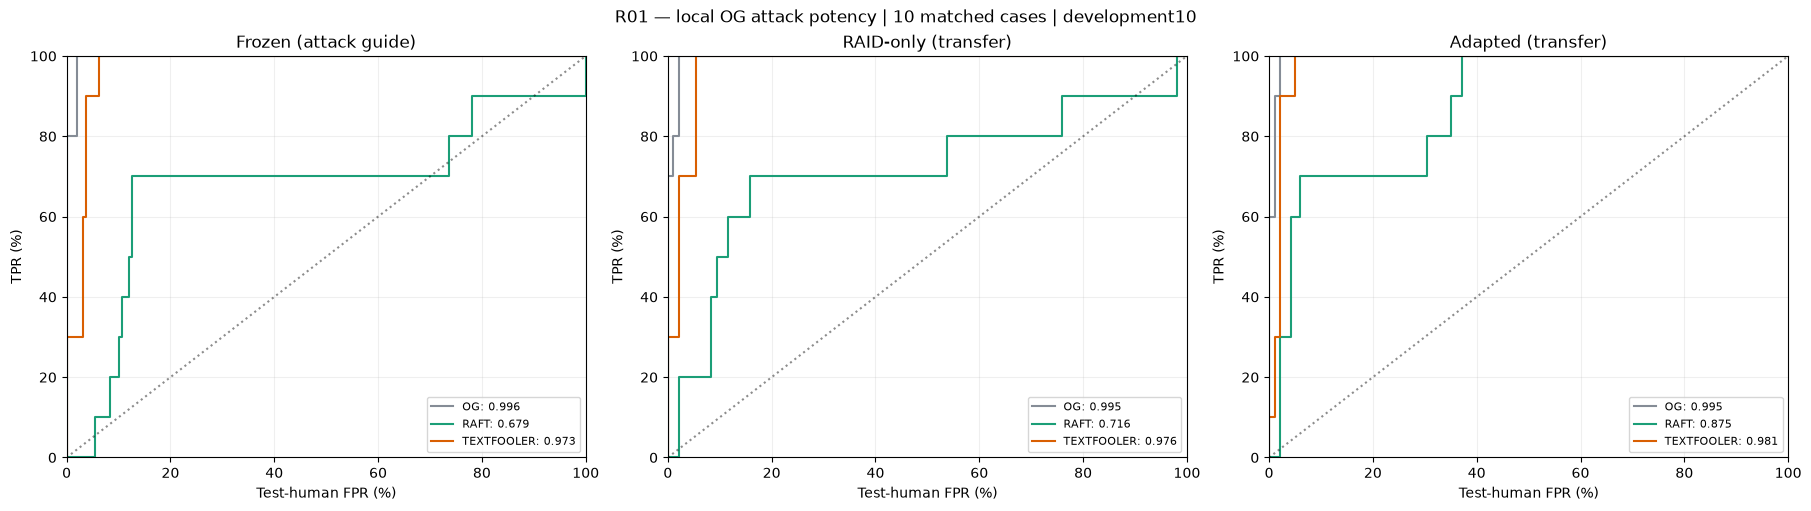

,detector,arm,cases,AUROC,ci_low,ci_high,mean_AI_score,mean_AI_log_odds,prefix_truncated
0,Frozen,OG,10,0.9959,0.9841,1.0000,0.9937,5.8797,1
1,Frozen,RAFT,10,0.6788,0.4507,0.8793,0.0328,-3.8320,0
2,Frozen,TEXTFOOLER,10,0.9729,0.9404,0.9953,0.5758,1.5194,1
3,RAID-only,OG,10,0.9954,0.9840,1.0000,0.9989,6.9625,1
4,RAID-only,RAFT,10,0.7165,0.4959,0.9032,0.2165,-2.6867,0
5,RAID-only,TEXTFOOLER,10,0.9756,0.9451,0.9962,0.9883,5.1859,1
6,Adapted,OG,10,0.9946,0.9800,1.0000,0.9994,7.4984,1
7,Adapted,RAFT,10,0.8746,0.7745,0.9582,0.5452,0.6947,0
8,Adapted,TEXTFOOLER,10,0.9810,0.9519,1.0000,0.9247,6.1796,1


,detector,comparison,cases,AUROC_delta,ci_low,ci_high,mean_log_odds_delta,decreased,increased
0,Frozen,RAFT_minus_OG,10,-0.3170,-0.5465,-0.1128,-9.7117,10,0
1,Frozen,TEXTFOOLER_minus_OG,10,-0.0230,-0.0520,-0.0037,-4.3602,7,0
2,RAID-only,RAFT_minus_OG,10,-0.2789,-0.5013,-0.0896,-9.6492,10,0
3,RAID-only,TEXTFOOLER_minus_OG,10,-0.0198,-0.0438,-0.0033,-1.7766,7,0
4,Adapted,RAFT_minus_OG,10,-0.1200,-0.2177,-0.0402,-6.8037,10,0
5,Adapted,TEXTFOOLER_minus_OG,10,-0.0136,-0.0338,0.0000,-1.3188,7,0


,detector,arm,nominal_FPR,threshold,validation_FPR,test_FPR,TPR
0,Frozen,OG,0.01,0.1514,0.0080,0.0317,1.0
2,Frozen,OG,0.05,-3.2734,0.0480,0.0901,1.0
6,Frozen,RAFT,0.01,0.1514,0.0080,0.0317,0.0
8,Frozen,RAFT,0.05,-3.2734,0.0480,0.0901,0.2
12,Frozen,TEXTFOOLER,0.01,0.1514,0.0080,0.0317,0.3
14,Frozen,TEXTFOOLER,0.05,-3.2734,0.0480,0.0901,1.0
18,RAID-only,OG,0.01,5.3906,0.0080,0.0206,1.0
20,RAID-only,OG,0.05,-2.9297,0.0449,0.0838,1.0
24,RAID-only,RAFT,0.01,5.3906,0.0080,0.0206,0.1
26,RAID-only,RAFT,0.05,-2.9297,0.0449,0.0838,0.3


Saved texts: ../results/causal/R01_published_local_v3/R01_all_completed_texts.csv
Manual review: ../results/causal/R01_published_local_v3/manual_review.csv
Figures: ../results/causal/R01_published_local_v3/figures


,detector,arm,originally_detected,escaped,ASR
0,Frozen,RAFT,10,10,1.0
1,Frozen,TEXTFOOLER,10,7,0.7
2,RAID-only,RAFT,10,8,0.8
3,RAID-only,TEXTFOOLER,10,0,0.0
4,Adapted,RAFT,10,4,0.4
5,Adapted,TEXTFOOLER,10,1,0.1


In [16]:
def human_weights(frame,mix):
    counts=frame.domain.value_counts()
    assert set(mix.index)<=set(counts.index),'Missing evaluation humans for a selected genre.'
    w=np.array([mix[d]/counts[d] for d in frame.domain],float)
    assert np.isclose(w.sum(),1)
    return w

def weighted_roc(a,h,w):
    thresholds=np.r_[np.inf,np.unique(np.r_[a,h])[::-1],-np.inf]
    fpr=np.array([w[h>=t].sum() for t in thresholds]);tpr=np.array([(a>=t).mean() for t in thresholds])
    return thresholds,fpr,tpr

def calibration_cut(values,weights,target):
    # >= decision; most permissive available cut satisfying validation FPR budget.
    cuts=np.r_[np.inf,np.unique(values)[::-1]]
    valid=[c for c in cuts if weights[values>=c].sum()<=target+1e-12]
    return min(valid)

summary=[];paired=[];stairs=[];operating=[]
n=len(matched);B=CFG['bootstrap'];rng=np.random.default_rng(CFG['seed'])
ai_boot=rng.integers(0,n,(B,n))
fig,axes=plt.subplots(1,len(EVAL_CHECKPOINTS),figsize=(6*len(EVAL_CHECKPOINTS),5),squeeze=False,constrained_layout=True)
colors=dict(OG='#858C96',RAFT='#1B9E77',TEXTFOOLER='#D95F02',EVOLUTION_SOURCE='#377EB8')
for ax,name in zip(axes[0],EVAL_CHECKPOINTS):
    f=scores.loc[scores.detector.eq(name)]
    hum=f.loc[f.arm.eq('Human')&f.split.eq('test')].reset_index(drop=True)
    cal=f.loc[f.arm.eq('Human')&f.split.eq('validation')].reset_index(drop=True)
    hs=hum.AI_log_odds.to_numpy();hw=human_weights(hum,mix)
    cs=cal.AI_log_odds.to_numpy();cw=human_weights(cal,mix)
    # Paired bootstrap: the same human resamples and AI-case indices for all arms.
    human_boot=np.zeros((B,len(hum)))
    for domain,group in hum.groupby('domain'):
        ix=group.index.to_numpy();draw=rng.integers(0,len(ix),(B,len(ix)))
        for b in range(B):human_boot[b,ix]=np.bincount(draw[b],minlength=len(ix))*mix[domain]/len(ix)
    values={};boot={};logs={}
    for arm in COMPARE_ARMS:
        g=f.loc[f.arm.eq(arm)].set_index('case_id').loc[matched]
        a=g.AI_log_odds.to_numpy();logs[arm]=a
        comp=(a[:,None]>hs)+.5*(a[:,None]==hs)
        auc=float((comp@hw).mean());values[arm]=auc
        per_case=comp@human_boot.T
        samples=per_case[ai_boot,np.arange(B)[:,None]].mean(1);boot[arm]=samples
        lo,hi=np.quantile(samples,[.025,.975])
        summary.append(dict(detector=name,arm=arm,cases=n,AUROC=auc,ci_low=lo,ci_high=hi,
            mean_AI_score=float(g.AI_score.mean()),mean_AI_log_odds=float(a.mean()),
            prefix_truncated=int(g.prefix_truncated.sum())))
        th,fp,tp=weighted_roc(a,hs,hw)
        ax.step(fp*100,tp*100,where='post',label=f'{arm}: {auc:.3f}',color=colors.get(arm))
        stairs.extend(dict(detector=name,arm=arm,threshold=t,test_FPR=x,TPR=y) for t,x,y in zip(th,fp,tp))
        for target in [.01,.025,.05,.10,.20,.50]:
            cut=calibration_cut(cs,cw,target)
            operating.append(dict(detector=name,arm=arm,nominal_FPR=target,threshold=cut,
                validation_FPR=float(cw[cs>=cut].sum()),test_FPR=float(hw[hs>=cut].sum()),TPR=float((a>=cut).mean())))
    for arm in COMPARE_ARMS:
        if arm=='OG':continue
        ds=boot[arm]-boot['OG'];lo,hi=np.quantile(ds,[.025,.975]);d=logs[arm]-logs['OG']
        paired.append(dict(detector=name,comparison=arm+'_minus_OG',cases=n,AUROC_delta=values[arm]-values['OG'],
            ci_low=lo,ci_high=hi,mean_log_odds_delta=float(d.mean()),decreased=int((d<0).sum()),increased=int((d>0).sum())))
    ax.plot([0,100],[0,100],'k:',alpha=.45)
    ax.set(xlim=(0,100),ylim=(0,100),xlabel='Test-human FPR (%)',ylabel='TPR (%)',title=name+(' (attack guide)' if name=='Frozen' else ' (transfer)'))
    ax.grid(alpha=.2);ax.legend(fontsize=8,loc='lower right')
fig.suptitle(f'R01 — local OG attack potency | {n} matched cases | {CASE_MODE}')
for ext in ['png','pdf']:fig.savefig(OUT/'figures'/('R01_staircases_'+CASE_MODE+'.'+ext),dpi=220)
plt.show();plt.close(fig)
summary=pd.DataFrame(summary);paired=pd.DataFrame(paired);stairs=pd.DataFrame(stairs);operating=pd.DataFrame(operating)
for name,df in [('summary',summary),('paired',paired),('staircase',stairs),('operating_points',operating)]:
    save_csv(df,OUT/(name+'_'+CASE_MODE+'.csv'))
display(summary.round(4));display(paired.round(4));display(operating.loc[operating.nominal_FPR.isin([.01,.05])].round(4))
print('Saved texts:',OUT/'R01_all_completed_texts.csv')
print('Manual review:',OUT/'manual_review.csv')
print('Figures:',OUT/'figures')
# ASR at the default classifier boundary, conditional on OG being correctly called AI.
asr=[]
for detector in EVAL_CHECKPOINTS:
    f=scores.loc[scores.detector.eq(detector)&scores.arm.ne('Human')]
    pivot=f.pivot(index='case_id',columns='arm',values='AI_log_odds').loc[matched]
    detected=pivot.OG.ge(0)
    for arm in COMPARE_ARMS:
        if arm=='OG':continue
        asr.append(dict(detector=detector,arm=arm,originally_detected=int(detected.sum()),
            escaped=int((detected & pivot[arm].lt(0)).sum()),
            ASR=float(pivot.loc[detected,arm].lt(0).mean()) if detected.any() else np.nan))
asr=pd.DataFrame(asr);save_csv(asr,OUT/('ASR_'+CASE_MODE+'.csv'));display(asr.round(4))

CUDA allocated 0.47 GiB; free 5.86 GiB
Frozen | NS10 1/10 | gate_0003 | cached
Frozen | NS10 2/10 | gate_0016 | cached
Frozen | NS10 3/10 | gate_0019 | cached
Frozen | NS10 4/10 | gate_0023 | cached
Frozen | NS10 5/10 | gate_0024 | cached
Frozen | NS10 6/10 | gate_0039 | cached
Frozen | NS10 7/10 | gate_0067 | cached
Frozen | NS10 8/10 | gate_0074 | cached
Frozen | NS10 9/10 | gate_0079 | cached
Frozen | NS10 10/10 | gate_0081 | cached
CUDA allocated 0.47 GiB; free 5.86 GiB
RAID-only | NS10 1/10 | gate_0003 | cached
RAID-only | NS10 2/10 | gate_0016 | cached
RAID-only | NS10 3/10 | gate_0019 | cached
RAID-only | NS10 4/10 | gate_0023 | cached
RAID-only | NS10 5/10 | gate_0024 | cached
RAID-only | NS10 6/10 | gate_0039 | cached
RAID-only | NS10 7/10 | gate_0067 | cached
RAID-only | NS10 8/10 | gate_0074 | cached
RAID-only | NS10 9/10 | gate_0079 | cached
RAID-only | NS10 10/10 | gate_0081 | cached
CUDA allocated 0.47 GiB; free 5.86 GiB
Adapted | NS10 1/10 | gate_0003 | cached
Adapted | 

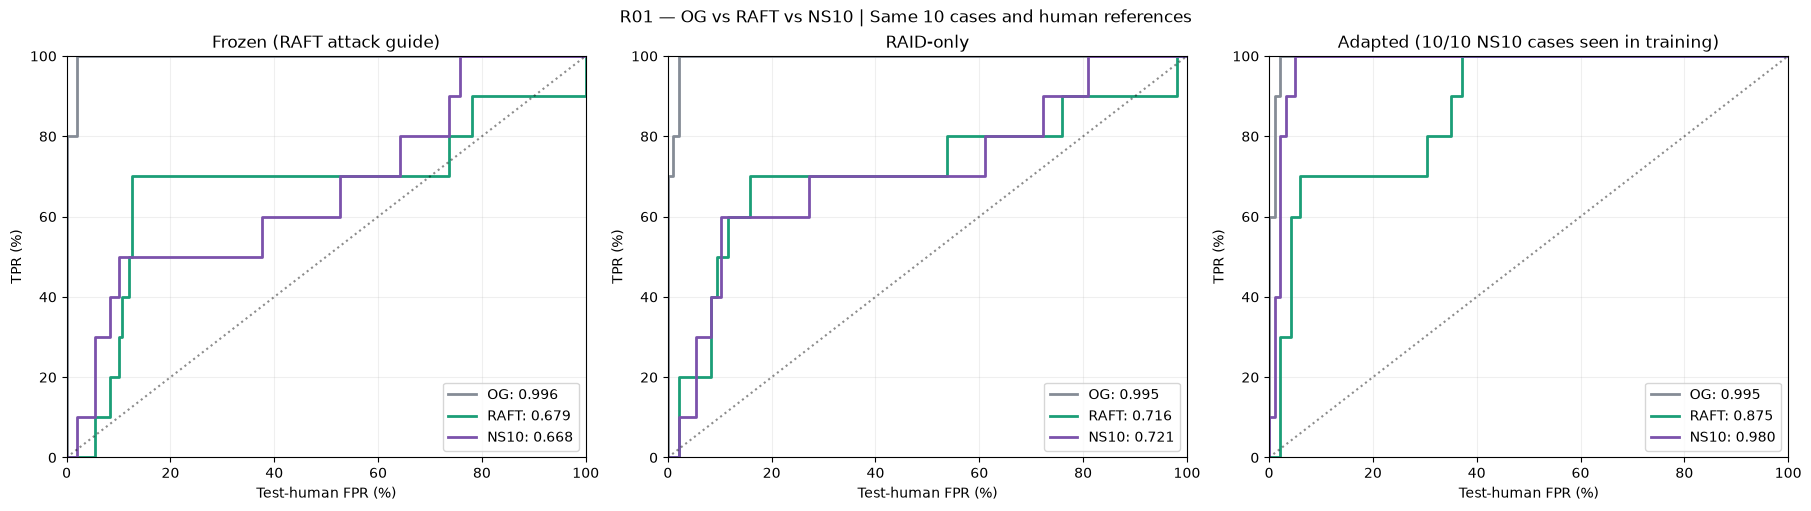

,detector,arm,cases,AUROC,mean_AI_score,mean_AI_log_odds
0,Frozen,OG,10,0.9959,0.9937,5.8797
1,Frozen,RAFT,10,0.6788,0.0328,-3.8320
2,Frozen,NS10,10,0.6678,0.1614,-2.7039
3,RAID-only,OG,10,0.9954,0.9989,6.9625
4,RAID-only,RAFT,10,0.7165,0.2165,-2.6867
5,RAID-only,NS10,10,0.7212,0.2948,-2.3180
6,Adapted,OG,10,0.9946,0.9994,7.4984
7,Adapted,RAFT,10,0.8746,0.5452,0.6947
8,Adapted,NS10,10,0.9803,0.9121,5.9887


,detector,arm,nominal_FPR,test_FPR,TPR
0,Frozen,OG,0.01,0.0317,1.0
1,Frozen,OG,0.05,0.0901,1.0
2,Frozen,OG,0.10,0.1069,1.0
3,Frozen,RAFT,0.01,0.0317,0.0
4,Frozen,RAFT,0.05,0.0901,0.2
5,Frozen,RAFT,0.10,0.1069,0.3
6,Frozen,NS10,0.01,0.0317,0.1
7,Frozen,NS10,0.05,0.0901,0.4
8,Frozen,NS10,0.10,0.1069,0.5
9,RAID-only,OG,0.01,0.0206,1.0


Saved: ../results/causal/R01_published_local_v3/RAFT_vs_NS10_matched10


In [17]:
# Matched OG vs RAFT vs NS10 — cached scoring, three detector panels.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

r01_scores = pd.read_csv(OUT / f"scores_{CASE_MODE}.csv")
case_ids = sorted(
    r01_scores.loc[
        r01_scores.detector.eq("Frozen") & r01_scores.arm.eq("RAFT"),
        "case_id"
    ].astype(str).unique()
)
assert len(case_ids) == 10, f"Expected 10 RAFT cases, found {len(case_ids)}."

ns10 = pd.read_csv(NS_PATH, keep_default_na=False)
ns10["case_id"] = ns10.case_id.astype(str)
assert ns10.case_id.is_unique
ns10 = ns10.set_index("case_id").loc[case_ids].reset_index()
assert ns10.text.map(lambda x: isinstance(x, str) and bool(x.strip())).all()

# Verify matching original sources.
originals = all_og.set_index("case_id").loc[case_ids]
assert ns10.source_id.tolist() == originals.source_id.tolist()
assert ns10.domain.tolist() == originals.domain.tolist()
mix = originals.domain.value_counts(normalize=True)

adaptation_ids = set(map(
    str, json.loads((AD / "split.json").read_text())["adaptation_cases"]
))
adaptation_overlap = len(set(case_ids) & adaptation_ids)

comparison_dir = OUT / "RAFT_vs_NS10_matched10"
comparison_dir.mkdir(exist_ok=True)
save_csv(ns10[["case_id", "source_id", "domain"]], comparison_dir / "cases.csv")

# Score only NS10. Each score is saved immediately and reused on rerun.
new_rows = []
with run_lock():
    try:
        unload_generator()
        unload_semantics()
        for detector in ["Frozen", "RAID-only", "Adapted"]:
            load_detector(CHECKPOINTS[detector])
            spec = digest([
                CP_SHA[detector], DTOK.backend_tokenizer.to_str(),
                CFG["detector_tokens"], str(DTYPE),
                transformers.__version__, torch.__version__,
            ])
            for i, row in enumerate(ns10.itertuples(index=False), 1):
                text_hash = sha(row.text)
                cache = OUT / "scores" / (digest([spec, text_hash]) + ".json")
                cached = cache.exists()
                if cached:
                    result = json.loads(cache.read_text())
                else:
                    result = detector_one(row.text)
                    result["full_tokens"] = len(
                        DTOK(row.text, truncation=False).input_ids
                    )
                    result["prefix_truncated"] = (
                        result["full_tokens"] > CFG["detector_tokens"]
                    )
                    atomic_json(cache, result)

                new_rows.append(dict(
                    detector=detector, case_id=row.case_id,
                    source_id=row.source_id, domain=row.domain,
                    split="test", arm="NS10", text_sha=text_hash, **result
                ))
                print(
                    f"{detector} | NS10 {i}/10 | {row.case_id}"
                    f" | {'cached' if cached else 'scored'}", flush=True
                )
    finally:
        unload_detector()

keep = (
    r01_scores.arm.eq("Human")
    | (
        r01_scores.arm.isin(["OG", "RAFT"])
        & r01_scores.case_id.astype(str).isin(case_ids)
    )
)
comparison = pd.concat(
    [r01_scores.loc[keep], pd.DataFrame(new_rows)], ignore_index=True
)
save_csv(comparison, comparison_dir / "matched_scores.csv")

arms = ["OG", "RAFT", "NS10"]
colors = {"OG": "#858C96", "RAFT": "#1B9E77", "NS10": "#7B52AB"}
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), constrained_layout=True
)
summary_rows, operating_rows = [], []

for ax, detector in zip(axes, ["Frozen", "RAID-only", "Adapted"]):
    frame = comparison.loc[comparison.detector.eq(detector)]
    human = frame.loc[frame.arm.eq("Human") & frame.split.eq("test")]
    cal = frame.loc[frame.arm.eq("Human") & frame.split.eq("validation")]
    assert human.source_id.is_unique and cal.source_id.is_unique

    hs = human.AI_log_odds.to_numpy()
    hw = human_weights(human, mix)
    cs = cal.AI_log_odds.to_numpy()
    cw = human_weights(cal, mix)

    for arm in arms:
        group = frame.loc[frame.arm.eq(arm)].set_index("case_id")
        assert group.index.is_unique
        group = group.loc[case_ids]
        values = group.AI_log_odds.to_numpy()

        auc = float((
            ((values[:, None] > hs)
             + 0.5 * (values[:, None] == hs)) @ hw
        ).mean())
        _, fpr, tpr = weighted_roc(values, hs, hw)
        ax.step(
            100 * fpr, 100 * tpr, where="post",
            color=colors[arm], lw=2, label=f"{arm}: {auc:.3f}"
        )
        summary_rows.append(dict(
            detector=detector, arm=arm, cases=len(values),
            AUROC=auc, mean_AI_score=group.AI_score.mean(),
            mean_AI_log_odds=values.mean(),
        ))

        for target in [.01, .05, .10]:
            threshold = calibration_cut(cs, cw, target)
            operating_rows.append(dict(
                detector=detector, arm=arm, nominal_FPR=target,
                test_FPR=float(hw[hs >= threshold].sum()),
                TPR=float((values >= threshold).mean()),
            ))

    title = detector
    if detector == "Frozen":
        title += " (RAFT attack guide)"
    elif detector == "Adapted":
        title += f" ({adaptation_overlap}/10 NS10 cases seen in training)"
    ax.plot([0, 100], [0, 100], "k:", alpha=.45)
    ax.set(
        title=title, xlim=(0, 100), ylim=(0, 100),
        xlabel="Test-human FPR (%)", ylabel="TPR (%)"
    )
    ax.grid(alpha=.2)
    ax.legend(loc="lower right")

fig.suptitle("R01 — OG vs RAFT vs NS10 | Same 10 cases and human references")
for extension in ["png", "pdf"]:
    fig.savefig(
        comparison_dir / f"RAFT_vs_NS10_matched10.{extension}", dpi=220
    )
plt.show()
plt.close(fig)

summary_table = pd.DataFrame(summary_rows)
operating_table = pd.DataFrame(operating_rows)
save_csv(summary_table, comparison_dir / "summary.csv")
save_csv(operating_table, comparison_dir / "operating_points.csv")

display(summary_table.round(4))
display(operating_table.round(4))
print("Saved:", comparison_dir)

In [18]:
import copy
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, DataCollatorWithPadding, set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

RAFT_AD = OUT / "RAFT_adaptation20_34"
for sub in ["", "training", "scores", "figures"]:
    (RAFT_AD / sub).mkdir(parents=True, exist_ok=True)

split_used = json.loads((AD / "split.json").read_text())
adapt_ids = list(map(str, split_used["adaptation_cases"]))
test_ids = list(map(str, split_used["test_cases"]))

assert len(adapt_ids) == len(set(adapt_ids)) == 20
assert len(test_ids) == len(set(test_ids)) == 34
assert not set(adapt_ids) & set(test_ids)
assert set(adapt_ids + test_ids) == set(all_og.case_id)
freeze(RAFT_AD / "split.json", split_used)

# Read the actual saved NS10 adaptation arguments.
arg_paths = [AD / "best_model/training_args.bin"]
arg_paths += sorted(
    (AD / "training").glob("checkpoint-*/training_args.bin"),
    key=lambda p: int(p.parent.name.split("-")[-1]),
    reverse=True,
)
arg_path = next((p for p in arg_paths if p.exists()), None)
assert arg_path is not None, f"Missing saved training_args.bin under {AD}"

ns10_train_args = torch.load(
    arg_path, map_location="cpu", weights_only=False
)
assert ns10_train_args.load_best_model_at_end
assert ns10_train_args.metric_for_best_model in ["loss", "eval_loss"]
assert ns10_train_args.greater_is_better is False

ns10_reference = pd.read_csv(NS_PATH, keep_default_na=False)
ns10_reference["case_id"] = ns10_reference.case_id.astype(str)
assert ns10_reference.case_id.is_unique
ns10_reference = ns10_reference.set_index("case_id").loc[
    adapt_ids + test_ids
].reset_index()

og_index = all_og.set_index("case_id")
assert ns10_reference.source_id.tolist() == (
    og_index.loc[adapt_ids + test_ids].source_id.tolist()
)

print("Adaptation:", len(adapt_ids), "| Held out:", len(test_ids))
print("NS10 training arguments:", arg_path)
display(pd.Series({
    k: getattr(ns10_train_args, k)
    for k in [
        "seed", "data_seed", "learning_rate", "num_train_epochs",
        "max_steps", "per_device_train_batch_size",
        "gradient_accumulation_steps", "eval_steps", "save_steps",
    ]
}))

Adaptation: 20 | Held out: 34
NS10 training arguments: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/best_model/training_args.bin


seed                           2.026092e+07
data_seed                      2.026092e+07
learning_rate                  1.000000e-05
num_train_epochs               3.000000e+00
max_steps                     -1.000000e+00
per_device_train_batch_size    1.000000e+00
gradient_accumulation_steps    1.600000e+01
eval_steps                     2.500000e+01
save_steps                     2.500000e+01
dtype: float64

In [19]:
import copy
from dataclasses import fields
from transformers import TrainingArguments

saved_values = vars(ns10_train_args).copy()
current_fields = {
    field.name for field in fields(TrainingArguments) if field.init
}

# Handle the evaluation-strategy rename across Transformers versions.
if (
    "eval_strategy" in current_fields
    and "eval_strategy" not in saved_values
    and "evaluation_strategy" in saved_values
):
    saved_values["eval_strategy"] = saved_values["evaluation_strategy"]

restored = {
    name: copy.deepcopy(value)
    for name, value in saved_values.items()
    if name in current_fields
}

ns10_train_args = TrainingArguments(**restored)

# Confirm the experimental settings were preserved.
for name in [
    "seed", "data_seed", "learning_rate", "num_train_epochs",
    "max_steps", "per_device_train_batch_size",
    "gradient_accumulation_steps", "weight_decay", "warmup_ratio",
    "eval_steps", "save_steps", "metric_for_best_model",
    "greater_is_better", "bf16", "fp16",
]:
    if name in saved_values:
        assert getattr(ns10_train_args, name) == saved_values[name], name

# Verify serialization now succeeds.
ns10_train_args.to_dict()
print("Training arguments repaired. Rerun Cell 3, then Cell 4.")

Training arguments repaired. Rerun Cell 3, then Cell 4.


In [20]:
with run_lock():
    try:
        unload_detector()
        unload_generator()
        unload_semantics()

        pending = [
            cid for cid in adapt_ids + test_ids
            if not complete(cid, "RAFT")
        ]
        print(f"RAFT: {len(pending)} remaining / 54", flush=True)

        if pending:
            load_generator()
            load_detector(CHECKPOINTS["Frozen"])

        for cid in pending:
            row = all_og.loc[all_og.case_id.eq(cid)].iloc[0]
            role = "adaptation20" if cid in adapt_ids else "heldout34"
            print(cid, role, flush=True)

            atomic_json(result_path(cid, "RAFT"), record_base(row, "RAFT"))
            try:
                run_raft(row)
            except BaseException as exc:
                state = read_result(cid, "RAFT") or record_base(row, "RAFT")
                state.update(status="interrupted", last_error=repr(exc))
                atomic_json(result_path(cid, "RAFT"), state)
                raise
    finally:
        unload_detector()
        unload_generator()

raft54 = pd.DataFrame([
    read_result(cid, "RAFT") for cid in adapt_ids + test_ids
])
assert len(raft54) == 54 and raft54.case_id.is_unique
assert raft54.status.eq("completed").all()
assert raft54.input_sha.tolist() == (
    og_index.loc[adapt_ids + test_ids].text_sha.tolist()
)

raft54["text_sha"] = raft54.text.map(sha)
raft54["role"] = np.where(
    raft54.case_id.isin(adapt_ids), "adaptation20", "heldout34"
)
save_csv(
    raft54[["case_id", "source_id", "domain", "text", "text_sha", "role"]],
    RAFT_AD / "RAFT_texts54.csv",
)
print("All 54 RAFT outputs saved.")

RAFT: 0 remaining / 54
All 54 RAFT outputs saved.


In [21]:
meta = pd.read_parquet(
    BASE / "fz118_paired_features.parquet",
    columns=["dataset", "source_id", "label", "split", "domain"],
)
corpus = pd.read_parquet(
    BASE / "paired_corpus.parquet", columns=["source_id", "text"]
)
assert meta.source_id.is_unique and corpus.source_id.is_unique

raid_adapt = meta.loc[meta.dataset.eq("raid")].merge(
    corpus, on="source_id", validate="one_to_one"
)
assert raid_adapt.text.notna().all()

clean_train = raid_adapt.loc[
    raid_adapt.split.eq("train")
].sort_values("source_id").reset_index(drop=True)
clean_val = raid_adapt.loc[
    raid_adapt.split.eq("validation")
].sort_values("source_id").reset_index(drop=True)

raft20 = raft54.set_index("case_id").loc[adapt_ids].reset_index()
raft20 = raft20.sort_values("case_id").reset_index(drop=True)
raft20["label"] = 1

training_frame = pd.concat([
    clean_train[["source_id", "domain", "text", "label"]],
    raft20[["source_id", "domain", "text", "label"]],
], ignore_index=True)

assert len(training_frame) == len(clean_train) + 20
assert not set(training_frame.source_id) & set(
    og_index.loc[test_ids].source_id
)
assert not set(training_frame.text.map(sha)) & set(clean_val.text.map(sha))
assert not set(training_frame.text.map(sha)) & set(
    raft54.set_index("case_id").loc[test_ids].text_sha
)

save_csv(
    raft20[["case_id", "source_id", "domain", "text", "text_sha", "label"]],
    RAFT_AD / "RAFT_adaptation20.csv",
)
save_csv(
    training_frame.assign(text_sha=training_frame.text.map(sha)).drop(columns="text"),
    RAFT_AD / "training_manifest.csv",
)

adapt_contract = dict(
    raft_run_sha=RUN_SHA,
    split=split_used,
    initialization=CP_SHA["Frozen"],
    reference_args_sha=file_sha(arg_path),
    reference_args=ns10_train_args.to_dict(),
    train_order="RAID sorted source_id, then RAFT sorted case_id",
    training=[
        [str(r.source_id), int(r.label), sha(r.text)]
        for r in training_frame.itertuples()
    ],
    validation=[
        [str(r.source_id), int(r.label), sha(r.text)]
        for r in clean_val.itertuples()
    ],
    max_tokens=CFG["detector_tokens"],
)
freeze(RAFT_AD / "contract.json", adapt_contract)
adapt_signature = digest(adapt_contract)

BEST_RAFT = RAFT_AD / "best_model"
DONE_RAFT = RAFT_AD / "training_complete.json"
TRAIN_RAFT = RAFT_AD / "training"

class AdaptDataset(torch.utils.data.Dataset):
    def __init__(self, frame, tokenizer):
        self.enc = tokenizer(
            frame.text.tolist(), truncation=True,
            max_length=CFG["detector_tokens"],
        )
        self.labels = frame.label.astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {
            **{k: v[i] for k, v in self.enc.items()},
            "labels": self.labels[i],
        }

with run_lock():
    if DONE_RAFT.exists():
        saved = json.loads(DONE_RAFT.read_text())
        assert saved["contract"] == adapt_signature
        assert saved["checkpoint_sha"] == digest(
            checkpoint_fingerprint(BEST_RAFT)
        )
        print("Using saved RAFT-adapted model.")
    else:
        unload_detector()
        unload_generator()
        release()
        set_seed(ns10_train_args.seed)

        adapt_tok = AutoTokenizer.from_pretrained(CHECKPOINTS["Frozen"])
        adapt_tok.truncation_side = "right"
        adapt_model = AutoModelForSequenceClassification.from_pretrained(
            CHECKPOINTS["Frozen"],
            torch_dtype=torch.float32,
            attn_implementation="eager",
            low_cpu_mem_usage=True,
        )

        args = copy.deepcopy(ns10_train_args)
        args.output_dir = str(TRAIN_RAFT)
        args.logging_dir = str(RAFT_AD / "logs")
        args.run_name = "RAFT_adaptation20"
        args.report_to = []
        args.push_to_hub = False
        args.hub_model_id = None
        args.hub_token = None

        trainer = Trainer(
            model=adapt_model,
            args=args,
            train_dataset=AdaptDataset(training_frame, adapt_tok),
            eval_dataset=AdaptDataset(clean_val, adapt_tok),
            data_collator=DataCollatorWithPadding(
                adapt_tok, pad_to_multiple_of=8
            ),
            tokenizer=adapt_tok,
        )
        last = get_last_checkpoint(str(TRAIN_RAFT))
        print("Resume:", last or "start from frozen checkpoint", flush=True)

        try:
            trainer.train(resume_from_checkpoint=last)
            trainer.save_model(str(BEST_RAFT))
            adapt_tok.save_pretrained(BEST_RAFT)
            atomic_json(RAFT_AD / "training_log.json", trainer.state.log_history)
            atomic_json(DONE_RAFT, dict(
                contract=adapt_signature,
                global_step=trainer.state.global_step,
                best_checkpoint=trainer.state.best_model_checkpoint,
                best_validation_loss=float(trainer.state.best_metric),
                checkpoint_sha=digest(checkpoint_fingerprint(BEST_RAFT)),
            ))
        finally:
            del trainer, adapt_model, adapt_tok
            release()

print("RAFT-adapted checkpoint:", BEST_RAFT)

Resume: start from frozen checkpoint


/tmp/ipykernel_449038/2359537264.py:122: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss,Validation Loss
25,0.107600,0.303462
50,0.168400,0.210533
75,0.111400,0.156082
100,0.098500,0.162866
125,0.026500,0.144648
150,0.070600,0.263102
175,0.069000,0.128768
200,0.029900,0.152456
225,0.056200,0.163352


RAFT-adapted checkpoint: ../results/causal/R01_published_local_v3/RAFT_adaptation20_34/best_model


CUDA allocated 0.53 GiB; free 5.68 GiB
Frozen 25 / 355
Frozen 50 / 355
Frozen 75 / 355
Frozen 100 / 355
Frozen 125 / 355
Frozen 150 / 355
Frozen 175 / 355
Frozen 200 / 355
Frozen 225 / 355
Frozen 250 / 355
Frozen 275 / 355
Frozen 300 / 355
Frozen 325 / 355
Frozen 350 / 355
CUDA allocated 0.53 GiB; free 5.68 GiB
RAFT-adapted 25 / 355
RAFT-adapted 50 / 355
RAFT-adapted 75 / 355
RAFT-adapted 100 / 355
RAFT-adapted 125 / 355
RAFT-adapted 150 / 355
RAFT-adapted 175 / 355
RAFT-adapted 200 / 355
RAFT-adapted 225 / 355
RAFT-adapted 250 / 355
RAFT-adapted 275 / 355
RAFT-adapted 300 / 355
RAFT-adapted 325 / 355
RAFT-adapted 350 / 355
CUDA allocated 0.53 GiB; free 5.68 GiB
NS10-adapted 25 / 355
NS10-adapted 50 / 355
NS10-adapted 75 / 355
NS10-adapted 100 / 355
NS10-adapted 125 / 355
NS10-adapted 150 / 355
NS10-adapted 175 / 355
NS10-adapted 200 / 355
NS10-adapted 225 / 355
NS10-adapted 250 / 355
NS10-adapted 275 / 355
NS10-adapted 300 / 355
NS10-adapted 325 / 355
NS10-adapted 350 / 355


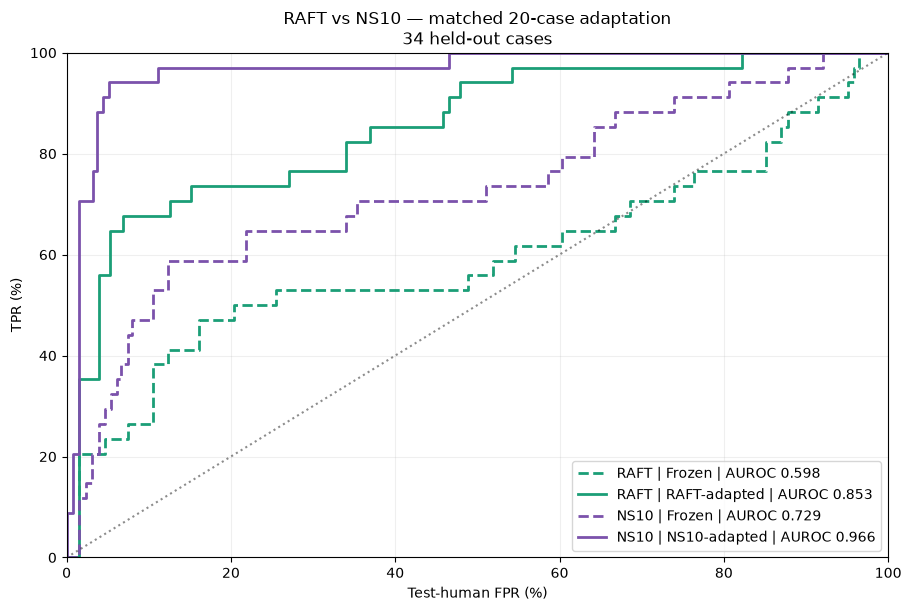

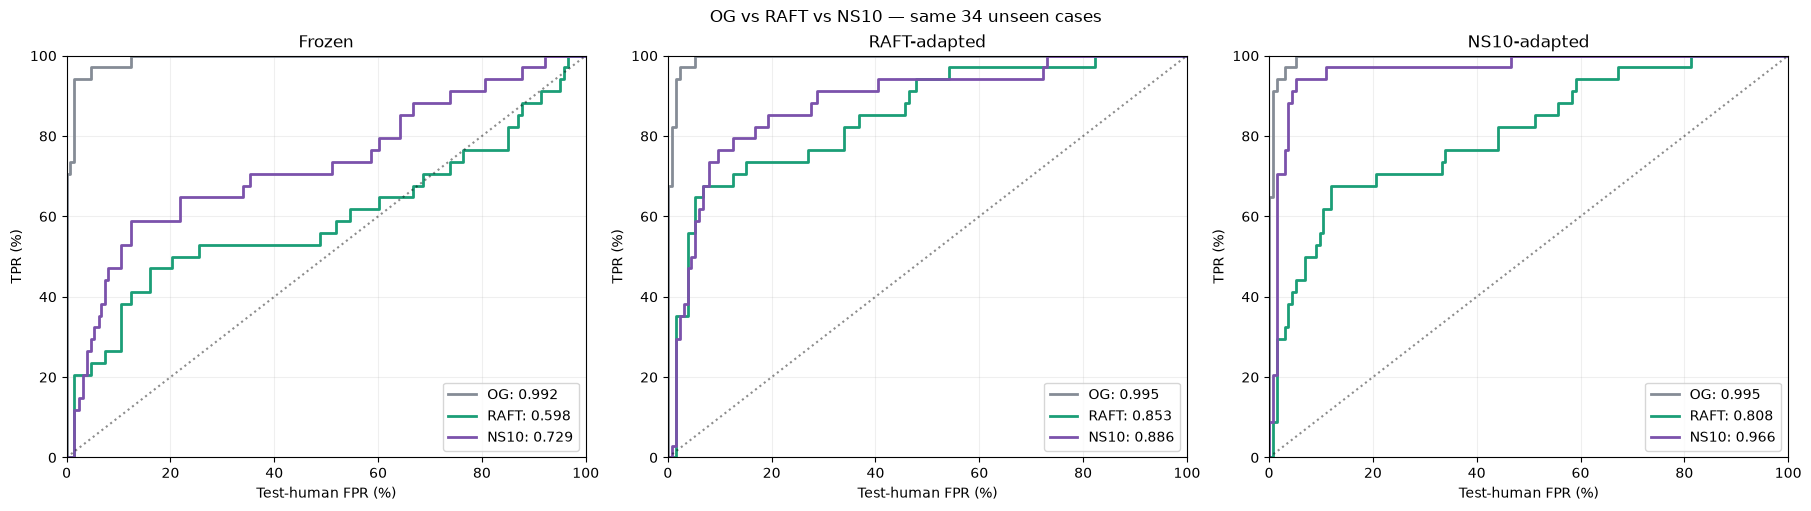

,detector,arm,cases,AUROC,mean_AI_score,mean_AI_log_odds
0,Frozen,OG,34,0.9917,0.9412,5.4238
1,Frozen,RAFT,34,0.5977,0.2106,-2.7120
2,Frozen,NS10,34,0.7291,0.1863,-2.5756
3,RAFT-adapted,OG,34,0.9949,0.9713,6.7551
4,RAFT-adapted,RAFT,34,0.8534,0.4556,0.0068
5,RAFT-adapted,NS10,34,0.8860,0.4271,-0.2877
6,NS10-adapted,OG,34,0.9951,0.9713,7.1946
7,NS10-adapted,RAFT,34,0.8082,0.3920,-0.7880
8,NS10-adapted,NS10,34,0.9657,0.8768,4.8691


,detector,arm,nominal_FPR,test_FPR,TPR
0,Frozen,OG,0.01,0.0152,0.9412
1,Frozen,OG,0.05,0.0748,0.9706
2,Frozen,OG,0.10,0.1053,0.9706
3,Frozen,OG,0.20,0.2183,1.0000
4,Frozen,RAFT,0.01,0.0152,0.2059
5,Frozen,RAFT,0.05,0.0748,0.2647
6,Frozen,RAFT,0.10,0.1053,0.2647
7,Frozen,RAFT,0.20,0.2183,0.5000
8,Frozen,NS10,0.01,0.0152,0.1176
9,Frozen,NS10,0.05,0.0748,0.4412


Saved: ../results/causal/R01_published_local_v3/RAFT_adaptation20_34


In [22]:
models_to_compare = {
    "Frozen": CHECKPOINTS["Frozen"],
    "RAFT-adapted": BEST_RAFT,
    "NS10-adapted": CHECKPOINTS["Adapted"],
}

ai_parts = []
for arm, frame in [
    ("OG", all_og), ("RAFT", raft54), ("NS10", ns10_reference)
]:
    part = frame.set_index("case_id").loc[test_ids].reset_index()
    part = part[["case_id", "source_id", "domain", "text"]].copy()
    part["arm"] = arm
    part["split"] = "test"
    ai_parts.append(part)

ai_eval = pd.concat(ai_parts, ignore_index=True)
assert not set(ai_eval.case_id) & set(adapt_ids)
mix34 = og_index.loc[test_ids].domain.value_counts(normalize=True)

human_eval = raid_adapt.loc[
    raid_adapt.label.eq(0)
    & raid_adapt.split.isin(["validation", "test"])
    & raid_adapt.domain.isin(mix34.index),
    ["source_id", "domain", "split", "text"],
].copy()
human_eval["case_id"] = ""
human_eval["arm"] = "Human"

docs34 = pd.concat([ai_eval, human_eval], ignore_index=True)
docs34["text_sha"] = docs34.text.map(sha)
frames34 = []

with run_lock():
    try:
        unload_generator()
        for name, checkpoint in models_to_compare.items():
            load_detector(checkpoint)
            signature = digest([
                digest(checkpoint_fingerprint(checkpoint)),
                DTOK.backend_tokenizer.to_str(),
                CFG["detector_tokens"], str(DTYPE),
                torch.__version__, transformers.__version__,
            ])
            values = {}
            unique = docs34[["text_sha", "text"]].drop_duplicates("text_sha")

            for i, row in enumerate(unique.itertuples(index=False), 1):
                path = RAFT_AD / "scores" / (
                    digest([signature, row.text_sha]) + ".json"
                )
                if path.exists():
                    result = json.loads(path.read_text())
                else:
                    result = detector_one(row.text)
                    atomic_json(path, result)
                values[row.text_sha] = result
                if i % 25 == 0:
                    print(name, i, "/", len(unique), flush=True)

            frame = docs34.drop(columns="text").copy()
            frame["detector"] = name
            for col in ["AI_score", "AI_log_odds"]:
                frame[col] = [values[h][col] for h in frame.text_sha]
            frames34.append(frame)
            save_csv(frame, RAFT_AD / f"{name}_scores.csv")
    finally:
        unload_detector()

scores34 = pd.concat(frames34, ignore_index=True)
save_csv(scores34, RAFT_AD / "heldout34_scores.csv")

curves, summary_rows, operating_rows = {}, [], []
for detector in models_to_compare:
    frame = scores34.loc[scores34.detector.eq(detector)]
    human = frame.loc[frame.arm.eq("Human") & frame.split.eq("test")]
    cal = frame.loc[frame.arm.eq("Human") & frame.split.eq("validation")]
    hs = human.AI_log_odds.to_numpy()
    cs = cal.AI_log_odds.to_numpy()
    hw = human_weights(human, mix34)
    cw = human_weights(cal, mix34)

    for arm in ["OG", "RAFT", "NS10"]:
        group = frame.loc[frame.arm.eq(arm)].set_index("case_id").loc[test_ids]
        values = group.AI_log_odds.to_numpy()
        _, fp, tp = weighted_roc(values, hs, hw)
        auc = float((
            ((values[:, None] > hs)
             + .5 * (values[:, None] == hs)) @ hw
        ).mean())
        curves[detector, arm] = fp, tp, auc
        summary_rows.append(dict(
            detector=detector, arm=arm, cases=34, AUROC=auc,
            mean_AI_score=group.AI_score.mean(),
            mean_AI_log_odds=values.mean(),
        ))
        for target in [.01, .05, .10, .20]:
            cut = calibration_cut(cs, cw, target)
            operating_rows.append(dict(
                detector=detector, arm=arm, nominal_FPR=target,
                test_FPR=float(hw[hs >= cut].sum()),
                TPR=float((values >= cut).mean()),
            ))

# Each method versus its OWN adapted detector.
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
for detector, arm, color, style in [
    ("Frozen", "RAFT", "#1B9E77", "--"),
    ("RAFT-adapted", "RAFT", "#1B9E77", "-"),
    ("Frozen", "NS10", "#7B52AB", "--"),
    ("NS10-adapted", "NS10", "#7B52AB", "-"),
]:
    fp, tp, auc = curves[detector, arm]
    ax.step(
        fp * 100, tp * 100, where="post",
        color=color, linestyle=style, lw=2,
        label=f"{arm} | {detector} | AUROC {auc:.3f}",
    )
ax.plot([0, 100], [0, 100], "k:", alpha=.45)
ax.set(
    xlim=(0, 100), ylim=(0, 100),
    xlabel="Test-human FPR (%)", ylabel="TPR (%)",
    title="RAFT vs NS10 — matched 20-case adaptation\n34 held-out cases",
)
ax.grid(alpha=.2)
ax.legend()
for ext in ["png", "pdf"]:
    fig.savefig(RAFT_AD / "figures" / f"own_adaptation34.{ext}", dpi=220)
plt.show()
plt.close(fig)

# Cross-method transfer on the same 34 held-out cases.
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
colors = {"OG": "#858C96", "RAFT": "#1B9E77", "NS10": "#7B52AB"}

for ax, detector in zip(axes, models_to_compare):
    for arm, color in colors.items():
        fp, tp, auc = curves[detector, arm]
        ax.step(
            fp * 100, tp * 100, where="post", color=color,
            lw=2, label=f"{arm}: {auc:.3f}",
        )
    ax.plot([0, 100], [0, 100], "k:", alpha=.45)
    ax.set(
        title=detector, xlim=(0, 100), ylim=(0, 100),
        xlabel="Test-human FPR (%)", ylabel="TPR (%)",
    )
    ax.grid(alpha=.2)
    ax.legend(loc="lower right")

fig.suptitle("OG vs RAFT vs NS10 — same 34 unseen cases")
for ext in ["png", "pdf"]:
    fig.savefig(RAFT_AD / "figures" / f"cross_transfer34.{ext}", dpi=220)
plt.show()
plt.close(fig)

summary34 = pd.DataFrame(summary_rows)
operating34 = pd.DataFrame(operating_rows)
save_csv(summary34, RAFT_AD / "summary.csv")
save_csv(operating34, RAFT_AD / "operating_points.csv")
display(summary34.round(4))
display(operating34.round(4))
print("Saved:", RAFT_AD)

## Interpretation and provenance

- This is a fresh experiment on the same ten development OG cases. Do not pool v2 and v3 attack results.
- RAFT and TextFooler now follow the identified released procedures; generator, target checkpoint, precision, and dataset differences are documented. This is not a promise to reproduce the papers' numerical results.
- Evolution's public classifier experiment is not fully specified by the code we located. `EVOLUTION_SOURCE` must retain that qualifier. It is not evidence for or against reproducing the reported Table 7 attack success rate.
- Frozen is directly queried during attacks. RAID-only and Adapted are transfer targets; Adapted was trained on NS10, not on these attacks.
- Cached stochastic candidate generation uses fixed per-prompt seeds. It is not an inherently deterministic attack.
- Inspect quality after generation and report invalid outputs rather than quietly excluding them from potency estimates.
- A classification-flip attack optimizes its original stopping criterion, not an entire ROC curve. Report conditional attack success alongside AUROC and calibrated TPR.

Sources (pinned commits and full-file hashes saved with each run):
1. Wang et al., *RAFT: Realistic Attacks to Fool Text Detectors*, EMNLP 2024: https://aclanthology.org/2024.emnlp-main.939/ ; https://github.com/JamesLWang/RAFT
2. Jin et al., *Is BERT Really Robust?*, AAAI 2020: https://arxiv.org/abs/1907.11932 ; https://github.com/jind11/TextFooler
3. Pu et al., *Deepfake Text Detection: Limitations and Opportunities*, IEEE S&P 2023: https://arxiv.org/abs/2210.09421 . Its TextFooler evaluation used its own perturbation budget. This notebook's TEXTFOOLER arm runs the original released TextFooler algorithm without that downstream study's ten-edit cap; it must not be called an exact replication of Pu et al.'s experiment.
4. Shi et al., *Red Teaming Language Model Detectors with Language Models*, TACL 2024: https://aclanthology.org/2024.tacl-1.10/ ; https://github.com/shizhouxing/LLM-Detector-Robustness

Validation here covers static syntax, embedded source fidelity, source-wrapper logic, and mocked checks. Real GPU generation and the original USE download must run on your machine.


In [23]:
from contextlib import contextmanager
from pathlib import Path
import json
import pandas as pd

NS11_OUT = ROOT / "results/causal/R11_NS10_RAFT_v1"

for sub in ["", "runs", "proposals", "ranks", "guide"]:
    (NS11_OUT / sub).mkdir(parents=True, exist_ok=True)

ns11_inputs = pd.read_csv(NS_PATH, keep_default_na=False)
ns11_inputs["case_id"] = ns11_inputs["case_id"].astype(str)

assert ns11_inputs.case_id.is_unique
assert set(ns11_inputs.case_id) == set(all_og.case_id)
assert len(ns11_inputs) == 54
assert "text" in ns11_inputs.columns

# Preserve the existing case metadata and adaptation/test partition.
ns11_inputs = (
    all_og[["case_id", "source_id", "domain", "partition"]]
    .merge(
        ns11_inputs[["case_id", "text"]],
        on="case_id",
        validate="one_to_one",
    )
    .sort_values("case_id")
    .reset_index(drop=True)
)
assert ns11_inputs.text.map(
    lambda text: isinstance(text, str) and bool(text.strip())
).all()

ns11_inputs["text_sha"] = ns11_inputs.text.map(sha)

# Stable experiment identity: no notebook-code hash.
ns11_protocol = {
    "method": "NS11 = existing R01 RAFT(NS10)",
    "config": CFG,
    "generator": PIN,
    "guide": CP_SHA["Frozen"],
    "inputs": ns11_inputs[
        ["case_id", "source_id", "text_sha", "partition"]
    ].to_dict("records"),
}

protocol_path = NS11_OUT / "protocol.json"
if protocol_path.exists():
    saved = json.loads(protocol_path.read_text())
    if saved != ns11_protocol:
        raise ValueError("NS11 inputs or configuration changed.")
else:
    atomic_json(protocol_path, ns11_protocol)

NS11_RUN_SHA = digest(ns11_protocol)
save_csv(ns11_inputs, NS11_OUT / "NS10_inputs.csv")


@contextmanager
def ns11_context():
    """Temporarily point existing RAFT helpers at the NS11 experiment."""
    global OUT, RUN_SHA, all_og

    previous = OUT, RUN_SHA, all_og
    try:
        OUT = NS11_OUT
        RUN_SHA = NS11_RUN_SHA
        all_og = ns11_inputs
        yield
    finally:
        OUT, RUN_SHA, all_og = previous


def export_ns11():
    rows = []
    with ns11_context():
        for row in ns11_inputs.itertuples(index=False):
            result = read_result(row.case_id, "RAFT")
            if result is None or result.get("status") != "completed":
                continue
            rows.append({
                "case_id": row.case_id,
                "source_id": row.source_id,
                "domain": row.domain,
                "partition": row.partition,
                "arm": "NS11",
                "text": result["text"],
                "text_sha": sha(result["text"]),
                "ns10_text_sha": row.text_sha,
                "accepted_edits": result.get("accepted_edits"),
                "edit_fraction": result.get("edit_fraction"),
                "successful_substitutions": result.get(
                    "successful_substitutions"
                ),
                "stop_reason": result.get("stop_reason"),
                "status": result["status"],
            })

    frame = pd.DataFrame(rows)
    if rows:
        save_csv(frame, NS11_OUT / "NS11_texts.csv")
    return frame


print("NS10 inputs:", len(ns11_inputs))
print("Output:", NS11_OUT)
print("Already completed:", len(export_ns11()))

NS10 inputs: 54
Output: ../results/causal/R11_NS10_RAFT_v1
Already completed: 0


In [24]:
ns11_results = None

with ns11_context():
    with run_lock():
        try:
            pending = [
                row
                for _, row in ns11_inputs.iterrows()
                if not complete(row.case_id, "RAFT")
            ]

            print(
                f"NS11: {54 - len(pending)}/54 completed; "
                f"{len(pending)} remaining.",
                flush=True,
            )

            if pending:
                unload_detector()
                unload_generator()
                load_generator()
                load_detector(CHECKPOINTS["Frozen"])

            for number, row in enumerate(pending, 1):
                print(
                    f"\n[{number}/{len(pending)}] "
                    f"{row.case_id} | {row.domain} | NS10 → NS11",
                    flush=True,
                )

                try:
                    run_raft(row)

                except BaseException as exc:
                    # Keep partial progress and cached candidates.
                    state = (
                        read_result(row.case_id, "RAFT")
                        or record_base(row, "RAFT")
                    )
                    if state.get("status") != "completed":
                        state.update(
                            status="interrupted",
                            last_error=repr(exc),
                        )
                        atomic_json(
                            result_path(row.case_id, "RAFT"), state
                        )
                    raise

                finally:
                    # Refresh the combined CSV after every case.
                    ns11_results = export_ns11()

        finally:
            unload_detector()
            unload_generator()

ns11_results = export_ns11()
print(f"\nSaved {len(ns11_results)}/54 NS11 texts.")
print(NS11_OUT / "NS11_texts.csv")

if not ns11_results.empty:
    display(ns11_results[
        [
            "case_id", "domain", "partition",
            "accepted_edits", "edit_fraction", "stop_reason",
        ]
    ])

NS11: 0/54 completed; 54 remaining.
CUDA allocated 0.06 GiB; free 6.24 GiB


Sliding Window Attention is enabled but not implemented for `eager`; unexpected results may be encountered.
Loading checkpoint shards: 100%|███████████████| 2/2 [00:03<00:00,  1.66s/it]

CUDA allocated 1.98 GiB; free 3.21 GiB


CUDA allocated 2.44 GiB; free 3.21 GiB

[1/54] gate_0001 | abstracts | NS10 → NS11
RAFT ranking 25 / 362
RAFT ranking 50 / 362
RAFT ranking 75 / 362
RAFT ranking 100 / 362
RAFT ranking 125 / 362
RAFT ranking 150 / 362
RAFT ranking 175 / 362
RAFT ranking 200 / 362
RAFT ranking 225 / 362
RAFT ranking 250 / 362
RAFT ranking 275 / 362
RAFT ranking 300 / 362
RAFT ranking 325 / 362
RAFT ranking 350 / 362
gate_0001 RAFT 1 / 36 replacements; 76
gate_0001 RAFT 1 / 36 replacements; 127
gate_0001 RAFT 2 / 36 replacements; 198
gate_0001 RAFT 2 / 36 replacements; 182
gate_0001 RAFT 2 / 36 replacements; 247
gate_0001 RAFT 3 / 36 replacements; 164
gate_0001 RAFT 3 / 36 replacements; 133
gate_0001 RAFT 3 / 36 replacements; 116
gate_0001 RAFT 3 / 36 replacements; 73
gate_0001 RAFT 4 / 36 replacements; 17
gate_0001 RAFT 5 / 36 replacements; 91
gate_0001 RAFT 5 / 36 replacements; 38
gate_0001 RAFT 5 / 36 replacements; 33
gate_0001 RAFT 5 / 36 replacements; 343
gate_0001 RAFT 5 / 36 replacements; 302
gate

Token indices sequence length is longer than the specified maximum sequence length for this model (613 > 512). Running this sequence through the model will result in indexing errors


RAFT ranking 25 / 445
RAFT ranking 50 / 445
RAFT ranking 75 / 445
RAFT ranking 100 / 445
RAFT ranking 125 / 445
RAFT ranking 150 / 445
RAFT ranking 175 / 445
RAFT ranking 200 / 445
RAFT ranking 225 / 445
RAFT ranking 250 / 445
RAFT ranking 275 / 445
RAFT ranking 300 / 445
RAFT ranking 325 / 445
RAFT ranking 350 / 445
gate_0004 RAFT 1 / 44 replacements; 43
gate_0004 RAFT 1 / 44 replacements; 0
gate_0004 RAFT 1 / 44 replacements; 67
gate_0004 RAFT 1 / 44 replacements; 147
gate_0004 RAFT 1 / 44 replacements; 182
gate_0004 RAFT 1 / 44 replacements; 101
gate_0004 RAFT 1 / 44 replacements; 143
gate_0004 RAFT 1 / 44 replacements; 129
gate_0004 RAFT 2 / 44 replacements; 184
gate_0004 RAFT 3 / 44 replacements; 158
gate_0004 RAFT 3 / 44 replacements; 75
gate_0004 RAFT 4 / 44 replacements; 109
gate_0004 RAFT 4 / 44 replacements; 186
gate_0004 RAFT 4 / 44 replacements; 315
gate_0004 RAFT 5 / 44 replacements; 151
gate_0004 RAFT 5 / 44 replacements; 189
gate_0004 RAFT 5 / 44 replacements; 160
gate_0

,case_id,domain,partition,accepted_edits,edit_fraction,stop_reason
0,gate_0001,abstracts,heldout34,37,0.102210,budget
1,gate_0003,news,development20,44,0.112245,budget
2,gate_0004,recipes,development20,44,0.098876,budget
3,gate_0005,reddit,heldout34,17,0.096591,budget
4,gate_0007,wiki,heldout34,61,0.117083,budget
5,gate_0015,abstracts,heldout34,45,0.106383,budget
6,gate_0016,books,development20,53,0.109504,budget
7,gate_0017,news,heldout34,36,0.100000,budget
8,gate_0018,recipes,heldout34,22,0.099099,budget
9,gate_0019,reddit,development20,35,0.102041,budget


In [25]:
ns11_results = export_ns11()

CASE_ID = "gate_0016"  # Change to inspect another case.

before = ns11_inputs.loc[ns11_inputs.case_id.eq(CASE_ID)]
after = (
    ns11_results.loc[ns11_results.case_id.eq(CASE_ID)]
    if not ns11_results.empty else pd.DataFrame()
)

if before.empty:
    print("Unknown case:", CASE_ID)
elif after.empty:
    print("NS11 has not completed for:", CASE_ID)
else:
    print(f"NS10 — {CASE_ID}\n")
    print(before.iloc[0]["text"])
    print(f"\n\nNS11 — {CASE_ID}\n")
    print(after.iloc[0]["text"])

NS10 — gate_0016

In the railway town of Shrewsbury, a famous portrait of Beatrice, a former fiancée, hangs in Stevens's London home. The faded photograph, a reminder of the life he left behind, sits above a pianoforte, hauntingly highlighting the choices Stevens made after their breakup. The occasion was a false engagement. And he is haunted by the questions concerning what could have been.  Stevens, a butler at Darlington Hall, has been devoted to serve his Master, the wealthy and influential Lord Darlington. Stevens has been a butler at Darlington Hall for over three decades, and his dedication to his profession is unwavering. He takes pride in maintaining the polite repute of his employer and ensuring that every guest feels welcome and at ease.  The 1930s loom large over Darlington Hall as Lord Darlington stirs from his slumber in partnership with two German scientists and politicians in matters that negatively impact the British Empire. Despite this, Stevens aspires to remain neut

In [28]:
import copy
from dataclasses import fields
from transformers import (
    TrainingArguments, Trainer, DataCollatorWithPadding,
    AutoTokenizer, AutoModelForSequenceClassification, set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

NS11_AD = NS11_OUT / "adaptation20_34"
NS11_TRAIN = NS11_AD / "training"
BEST_NS11 = NS11_AD / "best_model"
NS11_DONE = NS11_AD / "training_complete.json"

NS11_TRAIN.mkdir(parents=True, exist_ok=True)

split_ns11 = json.loads((AD / "split.json").read_text())
train_ids_ns11 = list(map(str, split_ns11["adaptation_cases"]))
test_ids_ns11 = list(map(str, split_ns11["test_cases"]))

assert len(set(train_ids_ns11)) == 20
assert len(set(test_ids_ns11)) == 34
assert not set(train_ids_ns11) & set(test_ids_ns11)

texts_ns11 = pd.read_csv(
    NS11_OUT / "NS11_texts.csv", keep_default_na=False
)
texts_ns11["case_id"] = texts_ns11.case_id.astype(str)
assert texts_ns11.case_id.is_unique
assert set(texts_ns11.case_id) == set(train_ids_ns11 + test_ids_ns11)

adapt20_ns11 = (
    texts_ns11.set_index("case_id")
    .loc[train_ids_ns11]
    .reset_index()
    .sort_values("case_id")
    .assign(label=1)
)

# Reconstruct the same original RAID train/validation data.
meta_ns11 = pd.read_parquet(
    BASE / "fz118_paired_features.parquet",
    columns=["dataset", "source_id", "label", "split", "domain"],
)
corpus_ns11 = pd.read_parquet(
    BASE / "paired_corpus.parquet",
    columns=["source_id", "text"],
)
raid_ns11 = meta_ns11.loc[meta_ns11.dataset.eq("raid")].merge(
    corpus_ns11, on="source_id", validate="one_to_one"
)
train_raid_ns11 = (
    raid_ns11.loc[raid_ns11.split.eq("train")]
    .sort_values("source_id").reset_index(drop=True)
)
val_ns11 = (
    raid_ns11.loc[raid_ns11.split.eq("validation")]
    .sort_values("source_id").reset_index(drop=True)
)

cols_ns11 = ["source_id", "domain", "text", "label"]
train_ns11 = pd.concat(
    [train_raid_ns11[cols_ns11], adapt20_ns11[cols_ns11]],
    ignore_index=True,
)

held_ns11 = texts_ns11.set_index("case_id").loc[test_ids_ns11]
assert len(train_ns11) == len(train_raid_ns11) + 20
assert not set(train_ns11.source_id) & set(held_ns11.source_id)
assert not set(train_ns11.text.map(sha)) & set(held_ns11.text.map(sha))
assert not set(train_ns11.text.map(sha)) & set(val_ns11.text.map(sha))

# Load the original adaptation settings; repair older saved argument objects.
arg_candidates_ns11 = [AD / "best_model" / "training_args.bin"]
arg_candidates_ns11 += sorted(
    (AD / "training").glob("checkpoint-*/training_args.bin"),
    key=lambda p: int(p.parent.name.split("-")[-1]),
    reverse=True,
)
arg_path_ns11 = next(
    (p for p in arg_candidates_ns11 if p.exists()), None
)
assert arg_path_ns11 is not None, "Saved adaptation training arguments missing."

raw_args_ns11 = vars(torch.load(
    arg_path_ns11, map_location="cpu", weights_only=False
)).copy()
valid_fields_ns11 = {
    f.name for f in fields(TrainingArguments) if f.init
}
if (
    "eval_strategy" in valid_fields_ns11
    and "eval_strategy" not in raw_args_ns11
    and "evaluation_strategy" in raw_args_ns11
):
    raw_args_ns11["eval_strategy"] = raw_args_ns11["evaluation_strategy"]

kwargs_ns11 = {
    k: copy.deepcopy(v)
    for k, v in raw_args_ns11.items()
    if k in valid_fields_ns11
}
kwargs_ns11.update(
    output_dir=str(NS11_TRAIN),
    logging_dir=str(NS11_AD / "logs"),
    run_name="NS11_adaptation20",
    report_to=[],
    push_to_hub=False,
    hub_model_id=None,
    hub_token=None,
)
args_ns11 = TrainingArguments(**kwargs_ns11)

assert args_ns11.load_best_model_at_end
assert args_ns11.metric_for_best_model in ["loss", "eval_loss"]
assert args_ns11.greater_is_better is False

# Record only experiment inputs/settings, not notebook code.
manifest_ns11 = {
    "split": split_ns11,
    "initialization": CP_SHA["Frozen"],
    "reference_args_sha": file_sha(arg_path_ns11),
    "max_tokens": CFG["detector_tokens"],
    "training": [
        [str(r.source_id), int(r.label), sha(r.text)]
        for r in train_ns11.itertuples()
    ],
    "validation": [
        [str(r.source_id), int(r.label), sha(r.text)]
        for r in val_ns11.itertuples()
    ],
}
freeze(NS11_AD / "manifest.json", manifest_ns11)
save_csv(adapt20_ns11, NS11_AD / "NS11_adaptation20.csv")


class NS11AdaptDataset(torch.utils.data.Dataset):
    def __init__(self, frame, tokenizer):
        self.enc = tokenizer(
            frame.text.tolist(),
            truncation=True,
            max_length=CFG["detector_tokens"],
        )
        self.labels = frame.label.astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {
            **{k: v[i] for k, v in self.enc.items()},
            "labels": self.labels[i],
        }


if NS11_DONE.exists():
    assert (BEST_NS11 / "config.json").exists()
    print("Reusing saved NS11-adapted model:", BEST_NS11)
else:
    unload_detector()
    unload_generator()
    release()
    set_seed(args_ns11.seed)

    tokenizer_ns11 = AutoTokenizer.from_pretrained(
        CHECKPOINTS["Frozen"], use_fast=True
    )
    tokenizer_ns11.truncation_side = "right"

    model_ns11 = AutoModelForSequenceClassification.from_pretrained(
        CHECKPOINTS["Frozen"],
        torch_dtype=torch.float32,
        attn_implementation="eager",
        low_cpu_mem_usage=True,
    )
    trainer_ns11 = None

    try:
        trainer_ns11 = Trainer(
            model=model_ns11,
            args=args_ns11,
            train_dataset=NS11AdaptDataset(train_ns11, tokenizer_ns11),
            eval_dataset=NS11AdaptDataset(val_ns11, tokenizer_ns11),
            data_collator=DataCollatorWithPadding(
                tokenizer_ns11, pad_to_multiple_of=8
            ),
            tokenizer=tokenizer_ns11,
        )

        resume_ns11 = get_last_checkpoint(str(NS11_TRAIN))
        print("Resume:", resume_ns11 or "Frozen RAID checkpoint")
        print("Training rows:", len(train_ns11), "| NS11 additions: 20")

        trainer_ns11.train(resume_from_checkpoint=resume_ns11)
        trainer_ns11.save_model(str(BEST_NS11))
        tokenizer_ns11.save_pretrained(BEST_NS11)

        atomic_json(
            NS11_AD / "training_log.json",
            trainer_ns11.state.log_history,
        )
        atomic_json(NS11_DONE, {
            "global_step": trainer_ns11.state.global_step,
            "best_checkpoint": trainer_ns11.state.best_model_checkpoint,
            "best_validation_loss": trainer_ns11.state.best_metric,
        })
        print("Saved NS11-adapted model:", BEST_NS11)

    finally:
        del trainer_ns11, model_ns11, tokenizer_ns11
        release()

/tmp/ipykernel_449038/3606527303.py:178: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_ns11 = Trainer(


Resume: Frozen RAID checkpoint
Training rows: 1292 | NS11 additions: 20


Step,Training Loss,Validation Loss
25,0.086700,0.161656
50,0.177200,0.247844
75,0.153800,0.135851
100,0.069300,0.147574
125,0.062300,0.169206
150,0.118700,0.186215
175,0.055200,0.150307
200,0.053700,0.135443
225,0.076200,0.160680


Saved NS11-adapted model: ../results/causal/R11_NS10_RAFT_v1/adaptation20_34/best_model


CUDA allocated 0.53 GiB; free 5.71 GiB

Frozen: 264 unique texts
  25/264 scored/cached
  50/264 scored/cached
  75/264 scored/cached
  100/264 scored/cached
  125/264 scored/cached
  150/264 scored/cached
  175/264 scored/cached
  200/264 scored/cached
  225/264 scored/cached
  250/264 scored/cached
  264/264 scored/cached
CUDA allocated 0.53 GiB; free 5.71 GiB

RAFT-adapted: 264 unique texts
  25/264 scored/cached
  50/264 scored/cached
  75/264 scored/cached
  100/264 scored/cached
  125/264 scored/cached
  150/264 scored/cached
  175/264 scored/cached
  200/264 scored/cached
  225/264 scored/cached
  250/264 scored/cached
  264/264 scored/cached
CUDA allocated 0.53 GiB; free 5.71 GiB

NS10-adapted: 264 unique texts
  25/264 scored/cached
  50/264 scored/cached
  75/264 scored/cached
  100/264 scored/cached
  125/264 scored/cached
  150/264 scored/cached
  175/264 scored/cached
  200/264 scored/cached
  225/264 scored/cached
  250/264 scored/cached
  264/264 scored/cached
CUDA alloc

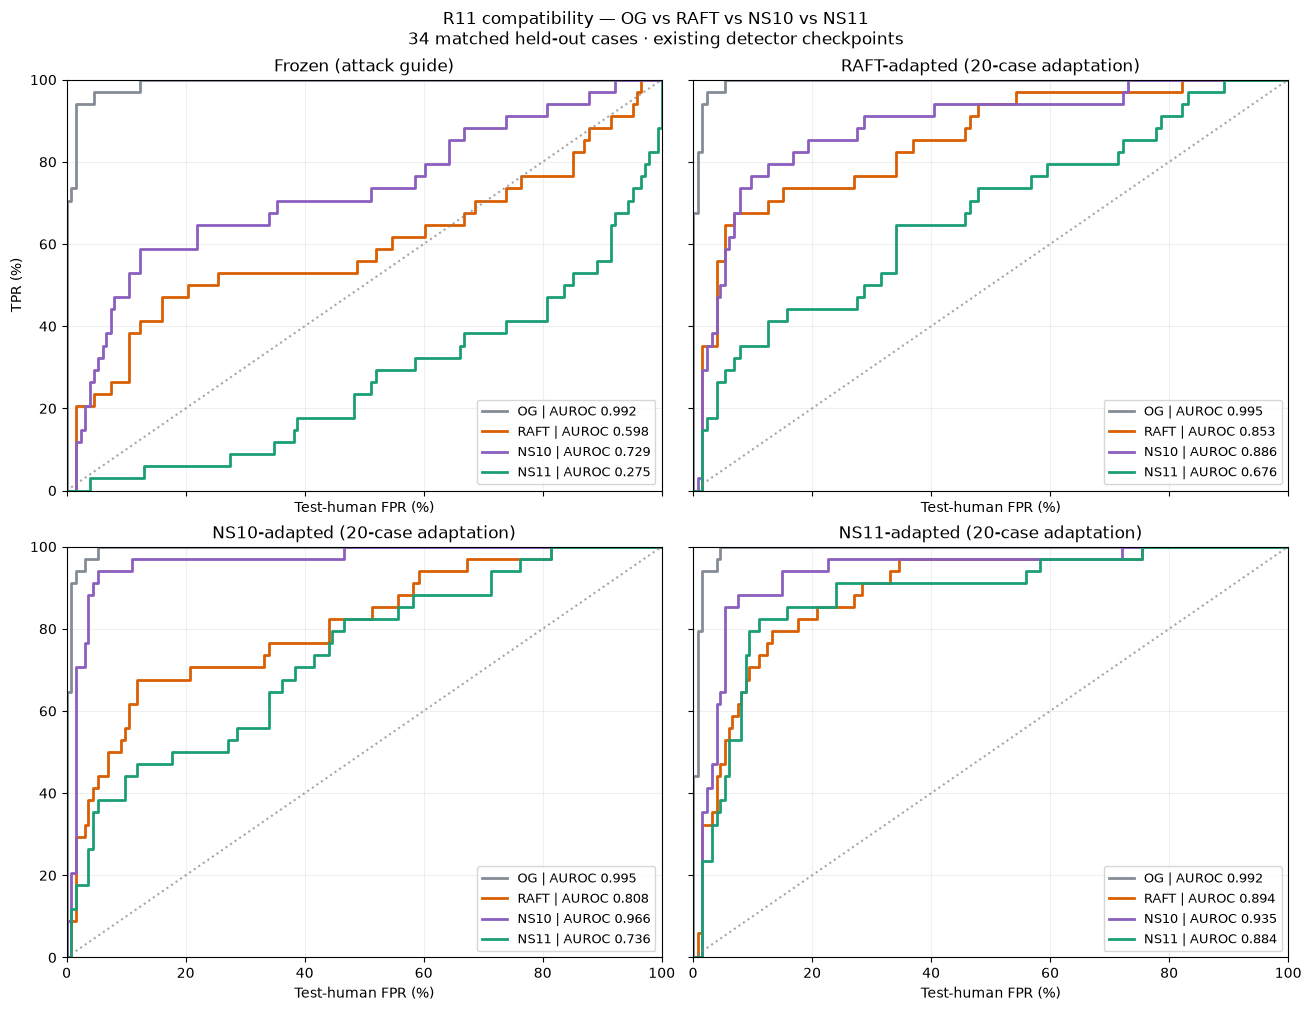

,detector,arm,cases,AUROC,mean_AI_score,mean_AI_log_odds
0,Frozen,OG,34,0.9917,0.9412,5.4238
1,Frozen,RAFT,34,0.5977,0.2106,-2.7120
2,Frozen,NS10,34,0.7291,0.1863,-2.5756
3,Frozen,NS11,34,0.2747,0.0178,-4.6190
4,RAFT-adapted,OG,34,0.9949,0.9713,6.7551
5,RAFT-adapted,RAFT,34,0.8534,0.4556,0.0068
6,RAFT-adapted,NS10,34,0.8860,0.4271,-0.2877
7,RAFT-adapted,NS11,34,0.6764,0.2128,-2.9253
8,NS10-adapted,OG,34,0.9951,0.9713,7.1946
9,NS10-adapted,RAFT,34,0.8082,0.3920,-0.7880


Saved: ../results/causal/R11_NS10_RAFT_v1/evaluation34


In [29]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

E11 = NS11_OUT / "evaluation34"
(E11 / "scores").mkdir(parents=True, exist_ok=True)

split11 = json.loads((AD / "split.json").read_text())
ids11 = list(map(str, split11["test_cases"]))
assert len(ids11) == len(set(ids11)) == 34

ns11_saved = pd.read_csv(
    NS11_OUT / "NS11_texts.csv", keep_default_na=False
)

og_raft11 = pd.read_csv(
    OUT / "RAFT_adaptation20_34" / "RAFT_texts54.csv",
    keep_default_na=False,
)

arms11 = {
    "OG": all_og,
    "RAFT": og_raft11,
    "NS10": ns11_inputs,
    "NS11": ns11_saved,
}

frames11 = []
for arm, frame in arms11.items():
    frame = frame.copy()
    frame["case_id"] = frame.case_id.astype(str)
    assert frame.case_id.is_unique
    missing = set(ids11) - set(frame.case_id)
    assert not missing, f"{arm}: missing cases {sorted(missing)}"

    frame = frame.set_index("case_id").loc[ids11].reset_index()
    frame = frame[["case_id", "source_id", "domain", "text"]]
    frame["arm"] = arm
    frames11.append(frame)

ai11 = pd.concat(frames11, ignore_index=True)
mix11 = (
    ai11.loc[ai11.arm.eq("OG"), "domain"]
    .value_counts(normalize=True)
)

hum11 = HUMAN_EVAL.loc[
    HUMAN_EVAL["split"].eq("test")
    & HUMAN_EVAL.domain.isin(mix11.index)
].copy().reset_index(drop=True)
assert len(hum11)
weights11 = human_weights(hum11, mix11)

models11 = {
    "Frozen": CHECKPOINTS["Frozen"],
    "RAFT-adapted": OUT / "RAFT_adaptation20_34" / "best_model",
    "NS10-adapted": CHECKPOINTS["Adapted"],
    "NS11-adapted": BEST_NS11,
}
for name, path in models11.items():
    assert path.exists(), f"Missing {name}: {path}"

texts11 = list(dict.fromkeys(
    ai11.text.tolist() + hum11.text.tolist()
))
scores11 = []

# Cache each text separately, so interrupted scoring can resume.
unload_generator()
try:
    for name, path in models11.items():
        checkpoint_sha = digest(checkpoint_fingerprint(path))
        load_detector(path)
        spec = {
            "checkpoint": checkpoint_sha,
            "tokenizer": DTOK.backend_tokenizer.to_str(),
            "max_tokens": CFG["detector_tokens"],
            "dtype": str(DTYPE),
            "torch": str(torch.__version__),
            "transformers": transformers.__version__,
        }
        predictions = {}

        print(f"\n{name}: {len(texts11)} unique texts", flush=True)
        for i, text in enumerate(texts11, 1):
            key = digest([spec, sha(text)])
            cache = E11 / "scores" / f"{key}.json"

            if cache.exists():
                value = json.loads(cache.read_text())
            else:
                value = detector_one(text)
                atomic_json(cache, value)

            predictions[text] = value
            if i % 25 == 0 or i == len(texts11):
                print(f"  {i}/{len(texts11)} scored/cached", flush=True)

        for row in ai11.to_dict("records"):
            scores11.append({
                **{k: row[k] for k in
                   ["case_id", "source_id", "domain", "arm"]},
                "detector": name,
                "text_sha": sha(row["text"]),
                **predictions[row["text"]],
            })

        for row in hum11.to_dict("records"):
            scores11.append({
                "case_id": "",
                "source_id": row["source_id"],
                "domain": row["domain"],
                "arm": "Human",
                "detector": name,
                "text_sha": sha(row["text"]),
                **predictions[row["text"]],
            })

        save_csv(pd.DataFrame(scores11), E11 / "scores34.csv")
        unload_detector()
finally:
    unload_detector()

scores11 = pd.DataFrame(scores11)

colors11 = {
    "OG": "#858C96",
    "RAFT": "#D95F02",
    "NS10": "#8B5FBF",
    "NS11": "#1B9E77",
}
summary11, stairs11 = [], []

fig, axes = plt.subplots(
    2, 2, figsize=(13, 10),
    sharex=True, sharey=True, constrained_layout=True,
)
axes = axes.ravel()

for ax, name in zip(axes, models11):
    scored = scores11.loc[scores11.detector.eq(name)]
    human = scored.loc[scored.arm.eq("Human")]
    hs = human.AI_log_odds.to_numpy()
    assert len(hs) == len(weights11)

    for arm in arms11:
        group = (
            scored.loc[scored.arm.eq(arm)]
            .set_index("case_id").loc[ids11]
        )
        values = group.AI_log_odds.to_numpy()

        # Genre-weighted human reference, equal AI-case weighting.
        comparisons = (
            (values[:, None] > hs[None, :]).astype(float)
            + 0.5 * (values[:, None] == hs[None, :])
        )
        auc = float((comparisons @ weights11).mean())

        thresholds, fpr, tpr = weighted_roc(
            values, hs, weights11
        )
        ax.step(
            100 * fpr, 100 * tpr, where="post",
            color=colors11[arm], linewidth=2,
            label=f"{arm} | AUROC {auc:.3f}",
        )

        summary11.append({
            "detector": name,
            "arm": arm,
            "cases": len(values),
            "AUROC": auc,
            "mean_AI_score": group.AI_score.mean(),
            "mean_AI_log_odds": values.mean(),
        })
        stairs11.extend({
            "detector": name, "arm": arm,
            "threshold": threshold,
            "test_FPR": fp, "TPR": tp,
        } for threshold, fp, tp in zip(thresholds, fpr, tpr))

    ax.plot([0, 100], [0, 100], ":", color="gray", alpha=.7)
    ax.set(
        title=name + (
            " (attack guide)" if name == "Frozen"
            else " (20-case adaptation)"
        ),
        xlabel="Test-human FPR (%)",
        xlim=(0, 100), ylim=(0, 100),
    )
    ax.grid(alpha=.2)
    ax.legend(loc="lower right", fontsize=9)

axes[0].set_ylabel("TPR (%)")
fig.suptitle(
    "R11 compatibility — OG vs RAFT vs NS10 vs NS11\n"
    "34 matched held-out cases · existing detector checkpoints"
)

for ext in ["png", "pdf"]:
    fig.savefig(E11 / f"NS11_staircases34.{ext}", dpi=220)
plt.show()
plt.close(fig)

summary11 = pd.DataFrame(summary11)
save_csv(summary11, E11 / "summary34.csv")
save_csv(pd.DataFrame(stairs11), E11 / "staircases34.csv")
display(summary11.round(4))

print("Saved:", E11)